# HerWILL Safe Social Media Datathon 2026: harmful-language classification

> **Content warning:** the posts in this project contain hate speech, slurs and harassment in Bangla, English and Banglish. Some cells (sections 1, 2 and 9) print example posts unfiltered.

**Task.** Classify each social-media post (Bangla, English or Banglish) as 0 = explicitly toxic, 1 = subtly toxic or 2 = neutral. **Metric:** Macro F1, the average of the three class F1 scores, so the small neutral class counts as much as the large ones.

**Our approach.** We clean the data once, fix one 5-fold cross-validation split, train four models on exactly the same folds (a TF-IDF baseline, XLM-RoBERTa large, BanglishBERT and Gemma 3 1B) and combine them in an ensemble. We tune the ensemble on 4 folds and score it on the 5th, so its score is not inflated by tuning.

### Results
All scores are out-of-fold (OOF): every training post is predicted by a model that did not see it during training, so these numbers estimate test performance.

| Model | Macro F1 | Explicit | Subtle | Neutral | English | Bangla |
|---|---|---|---|---|---|---|
| TF-IDF + logistic regression (baseline) | 0.5264 | 0.646 | 0.506 | 0.428 | 0.551 | 0.452 |
| BanglishBERT (Bangla-English encoder) | 0.5505 | 0.671 | 0.510 | 0.471 | 0.582 | 0.477 |
| XLM-RoBERTa large (multilingual encoder) | 0.5768 | 0.698 | 0.512 | 0.520 | 0.619 | 0.477 |
| Gemma 3 1B + LoRA (small LLM) | 0.5889 | 0.698 | 0.534 | 0.535 | 0.636 | 0.471 |
| **Final ensemble of all four (honest)** | **0.6057** | 0.700 | 0.561 | 0.556 | 0.646 | 0.500 |

The ensemble beats our best single model by +0.017, and its 5 fold scores are close together (0.602-0.613).

### How this notebook is organised
- Each section starts with a short explanation of what we do and why, and each code cell has a note saying what it does and which output to check.
- We keep the long jobs in small scripts (`src/*.py`). The notebook writes them with `%%writefile` and runs them as separate processes, so everything is in one file and a crash during training does not stop the notebook.
- Every step saves its results to Google Drive and skips work that is already done. That is why some training cells print `predictions exist, nothing to do`: we trained those models in an earlier session of this notebook. Their records are the loss curves (10.8a), the model table (10.8b) and the run log `results/runs.csv`, except XLM-R fold 0, which we trained in our first session (see 10.4).

### How to reproduce
Upload this project folder to `MyDrive/herwill_datathon/` (the competition CSVs go in its `data/` folder), open this notebook in Google Colab with a T4 GPU and choose *Runtime -> Run all*. After a disconnect, run all again; finished steps are skipped. GPU results come out close to ours but not bit-identical, which is normal for GPU training.

## Contents

| § | Section | What it answers | Runs on |
|---|---|---|---|
| 0 | Setup | Same software for everyone (pinned versions) | CPU |
| 1 | Outliers and duplicates | Is the raw data clean? | CPU |
| 2 | Test set exploration | Does the test set look like the training set? | CPU |
| 3 | URLs, mentions, hashtags, emojis | What should cleaning keep or replace? | CPU |
| 4 | Cleaning | Remove the outlier, merge duplicate posts | CPU |
| 5 | Preprocessing | The one text-cleaning function every model uses | CPU |
| 6 | Folds | One fixed, leak-free 5-fold split | CPU |
| 7 | Baseline | How far does a simple model get? | CPU |
| 8 | Evaluation | Scores per class and per language | CPU |
| 9 | Error analysis | Where and why do models fail? | CPU |
| 10 | Transformers and Gemma | Stronger models, training curves, model comparison | **GPU** |
| 11 | Ensembling | Combining the models, scored honestly | CPU |
| 12 | Final submission | Build, check and explain the submitted file | CPU |
| 13 | Summary for presentation | A short summary of the whole project | CPU |

### Time to reproduce everything on a Colab T4

| Step | Time | Source |
|---|---|---|
| 0-6 Setup, exploration, cleaning, folds | ~5 min | estimate |
| 7 TF-IDF baseline, 5 folds | ~4 min (0.9 min per fold) | measured |
| 10 XLM-RoBERTa large, 5 folds | ~2.5 h (29.8 min per fold) | measured |
| 10 BanglishBERT, 5 folds | ~46 min (9.1 min per fold) | measured |
| 10 Gemma 3 1B + LoRA, 5 folds | ~4 h (47.5 min per fold) | measured |
| 11-13 Ensemble, submission, summary | ~5 min | estimate |
| **Total** | **~7.5 h on one T4** | mostly measured; section 12.3 prints the measured total |

## 0. Setup

Here we connect Google Drive, move into the project folder and install pinned package versions, so anyone rerunning the notebook gets the same software we used.

We pin scikit-learn because our fold split (section 6) comes from its `StratifiedGroupKFold`, which shuffles differently from version 1.8 on. Version 1.7.2 reproduces our folds exactly: we tested 1.6.1 and 1.7.2, which give identical folds, and 1.8.0 and 1.9.1, which do not. If Colab has already loaded another version, the cell stops and asks for a runtime restart.

> **Cell 0.1.** We connect Google Drive, install the pinned package versions and remove an old Colab package (`torchao`) that breaks the LoRA library we use for Gemma.  
> **Output:** the last line shows the GPU and the library versions.

In [1]:
# ============================================================
# 0.1 Drive, project folder, pinned packages, GPU check
# ============================================================
import os, sys, subprocess, importlib.metadata as md

IN_COLAB = "google.colab" in sys.modules
PROJECT = os.environ.get("HERWILL_ROOT") or ("/content/drive/MyDrive/herwill_datathon" if IN_COLAB else os.getcwd())
PINS = {"scikit-learn": "1.7.2", "transformers": "5.16.1", "datasets": "5.0.1", "peft": "0.21.0"}
NORMALIZER = "git+https://github.com/csebuetnlp/normalizer@d405944dde5ceeacb7c2fd3245ae2a9dea5f35c9"  # BanglishBERT text normalizer

def installed(pkg):
    try:
        return md.version(pkg)
    except md.PackageNotFoundError:
        return None

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
os.chdir(PROJECT)                     # everything is read from and written to the project folder
assert os.path.exists("data/train.csv"), f"data/train.csv not found in {PROJECT}: put the competition files in data/"
os.makedirs("src", exist_ok=True)     # %%writefile cells below need the folder to exist

need = [f"{p}=={v}" for p, v in PINS.items() if installed(p) != v]
if installed("normalizer") is None:
    need.append(NORMALIZER)
if need and IN_COLAB:
    print("installing:", need)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *need], check=True)
# Colab ships torchao 0.10; peft 0.21 refuses torchao < 0.16 and crashes LoRA (Gemma). This project never
# uses torchao (it is for quantisation), so we remove an old copy; peft then skips it.
if IN_COLAB and installed("torchao") and tuple(int(x) for x in installed("torchao").split(".")[:2]) < (0, 16):
    print(f"removing incompatible torchao {installed('torchao')}")
    subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "torchao"], check=True)

stale = [p for p, mod in [("scikit-learn", "sklearn"), ("transformers", "transformers"), ("datasets", "datasets"), ("peft", "peft")]
         if mod in sys.modules and getattr(sys.modules[mod], "__version__", PINS[p]) != PINS[p]]
wrong = {p: installed(p) for p in PINS if installed(p) != PINS[p]}
if stale:
    raise RuntimeError(f"Old versions of {stale} are already loaded. Runtime -> Restart session, then run from section 0 again.")
if wrong:
    raise RuntimeError(f"Wrong package versions {wrong}; expected {PINS}. In Colab rerun this cell; locally install the pinned versions.")

import shutil
gpu = subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"],
                     capture_output=True, text=True).stdout.strip() if shutil.which("nvidia-smi") else ""
print(f"project folder: {os.getcwd()}")
print(f"GPU: {gpu or 'none (CPU only)'} | python {sys.version.split()[0]} | " + " | ".join(f"{p} {installed(p)}" for p in PINS))

Mounted at /content/drive
installing: ['scikit-learn==1.7.2', 'datasets==5.0.1', 'peft==0.21.0', 'git+https://github.com/csebuetnlp/normalizer@d405944dde5ceeacb7c2fd3245ae2a9dea5f35c9']
removing incompatible torchao 0.10.0
project folder: /content/drive/MyDrive/herwill_datathon
GPU: Tesla T4, 15360 MiB | python 3.13.15 | scikit-learn 1.7.2 | transformers 5.16.1 | datasets 5.0.1 | peft 0.21.0


### 0.2 `src/common.py`: shared code

Every script and cell imports this file, so the paths, random seed, text-cleaning function, metric and file names are defined once. We did this so that no two models can end up trained on differently cleaned text.

> **Cell 0.2.** We write `src/common.py`, the helper file every script shares (paths, seed, cleaning function, metric, file names, run log).  
> **Output:** `Writing` or `Overwriting src/common.py`.

In [2]:
%%writefile src/common.py
# ============================================================
# 0.2 src/common.py: paths, seed, clean(), metrics, prediction files, run log
# ============================================================
"""
common.py - shared code for every script and notebook cell: paths, seed,
text cleaning, metrics, prediction files and the run log.
Written by the notebook (section 0.2); we edit it there, not by hand.
"""
import os, re, glob, json, unicodedata
from datetime import datetime
import numpy as np
import pandas as pd

VERSION = "2026-09-28.2"

# ---------------------------------------------------------------- paths
# ROOT = the project folder (the one holding data/train.csv). common.py lives in
# ROOT/src, so ROOT is its parent folder; HERWILL_ROOT overrides it (tests).
ROOT = os.environ.get("HERWILL_ROOT") or os.path.dirname(os.path.dirname(os.path.abspath(__file__)))
TRAIN_RAW    = f"{ROOT}/data/train.csv"                  # competition files: read-only
TEST_RAW     = f"{ROOT}/data/test.csv"
SAMPLE_SUB   = f"{ROOT}/data/sample_submission.csv"
ARCHIVE_DIR  = f"{ROOT}/_archive_v1"                # our first-version files (used only to check the folds)
DATA_DIR     = f"{ROOT}/data"
TRAIN_FOLDS  = f"{DATA_DIR}/train_folds.csv"        # FROZEN: every prediction depends on its folds
TEST_LANG    = f"{DATA_DIR}/test_lang.csv"
TEST_OVERLAP = f"{DATA_DIR}/test_overlap.csv"

# SMOKE mode (quick end-to-end test on a small sample): model outputs go to
# ROOT/_smoke/..., so a test run can never overwrite real results.
SMOKE = os.environ.get("HERWILL_SMOKE") == "1"
OUT_DIR     = f"{ROOT}/_smoke" if SMOKE else ROOT
PRED_DIR    = f"{OUT_DIR}/preds"
RESULTS_DIR = f"{OUT_DIR}/results"
HISTORY_DIR = f"{RESULTS_DIR}/history"
FIG_DIR     = f"{RESULTS_DIR}/figures"
SUB_DIR     = f"{OUT_DIR}/submissions"
RUNLOG      = f"{RESULTS_DIR}/runs.csv"

SEED, N_FOLDS = 42, 5
LABELS = {0: "explicit", 1: "subtle", 2: "neutral"}
COLS = ["p0", "p1", "p2"]
LANGS = ["english", "bangla", "banglish", "mixed_script"]
SMOKE_TRAIN_PER_FOLD, SMOKE_TEST_ROWS = 100, 200

# ---------------------------------------------------------------- text processing
# clean(): we use this one function for every model, so no two models see
# differently cleaned text.
URL_RE = re.compile(r"https?://\S+|www\.\S+")
MENTION_RE = re.compile(r"@\w+")
REPEAT_RE = re.compile(r"(\D)\1{3,}")   # 4+ repeats -> 3; digits untouched

def clean(t):
    t = unicodedata.normalize("NFKC", str(t))
    t = URL_RE.sub("URL", t)
    t = MENTION_RE.sub("@USER", t)
    t = REPEAT_RE.sub(r"\1\1\1", t)
    return re.sub(r"\s+", " ", t).strip()

# norm_key(): near-duplicate key (lower case, no URLs/mentions/punctuation,
# emojis kept). lang_tag(): script-based language tag. We kept both unchanged
# from our first version, which is why the folds reproduce exactly.
def norm_key(t):
    k = unicodedata.normalize("NFKC", t).lower()
    k = re.sub(r"https?://\S+|www\.\S+|@\w+", " ", k)
    k = re.sub(r"[^\w\sঀ-৿\U0001F000-\U0001FAFF☀-➿]+", " ", k)
    k = re.sub(r"\s+", " ", k).strip()
    return k if k else "raw::" + t

BANGLISH = set("""
ami amra tumi tomra apni apnara tui tora se tara amar tomar apnar tor tar oder
ki keno kemne kemon kobe kothay kake kar koto kire
na nai nah naki ni hoy hoi hobe hoilo hoise hoyeche hoye hocche hoche ache ase asi
chilo silo thake theke thik kore korse korche korlo korbo korben koren korish kor
bole bolo bollo bolche bolse dekhe dekho dekhlam dekhen lage lagche lagse lagbe
valo bhalo vallo kharap khub onek beshi besi kom sob shob sobai shobai kichu kisu
ekta eta oita ota ei oi etai shei sei tai tahole jodi kintu abar arekta
bhai vai bhaiya apu dada didi mama kaka shala sala shaala magi pagol pagla
jonno jnno diye dia niye nia pore age pare parbe parish mone jani janina bujhi
desh manush manus kaj kotha din rat shesh sesh hashi haha lol vua bhua
""".split())

def lang_tag(t):
    bn = len(re.findall(r"[ঀ-৿]", t))
    lat = len(re.findall(r"[A-Za-z]", t))
    if bn + lat == 0:
        return "other"
    r = bn / (bn + lat)
    if r > 0.85:
        return "bangla"
    if r >= 0.15:
        return "mixed_script"
    toks = re.findall(r"[a-z]+", t.lower())
    hits = sum(w in BANGLISH for w in toks)
    if hits >= 2 or (toks and hits / len(toks) >= 0.25):
        return "banglish"
    return "english"

# ---------------------------------------------------------------- data
def load_data():
    """Prepared train (with frozen folds) and test, restricted to the SMOKE
    sample when SMOKE is on. Every script uses this, so all models always
    cover exactly the same rows."""
    train_df = pd.read_csv(TRAIN_FOLDS)
    test_df = pd.read_csv(TEST_LANG)
    train_df["text"] = train_df["text"].fillna("").astype(str)
    test_df["text"] = test_df["text"].fillna("").astype(str)
    if SMOKE:
        train_df = train_df.groupby("fold").head(SMOKE_TRAIN_PER_FOLD).reset_index(drop=True)
        test_df = test_df.head(SMOKE_TEST_ROWS).reset_index(drop=True)
    return train_df, test_df

# ---------------------------------------------------------------- metrics
def confusion(y, pred, k=3):
    return np.bincount(np.asarray(y) * k + np.asarray(pred), minlength=k * k).reshape(k, k)

def f1_per_class(y, pred, k=3):
    cm = confusion(y, pred, k)
    tp = np.diag(cm); fp = cm.sum(0) - tp; fn = cm.sum(1) - tp
    return 2 * tp / np.maximum(2 * tp + fp + fn, 1)

def macro_f1(y, pred, k=3):
    return f1_per_class(y, pred, k).mean()

def report(y, pred, lang=None, name="", show_cm=False, quiet=False):
    """Compact summary; returns the numbers as a flat dict (for the run log)."""
    y, pred = np.asarray(y), np.asarray(pred)
    pc = f1_per_class(y, pred)
    out = {"macro_f1": round(macro_f1(y, pred), 4),
           **{f"f1_{c}": round(v, 4) for c, v in enumerate(pc)}, "n": len(y)}
    if lang is not None:
        lang = np.asarray(lang)
        for lg in LANGS:
            m = lang == lg
            if m.any():
                out[f"f1_{lg}"] = round(macro_f1(y[m], pred[m]), 4)
    if not quiet:
        print(f"{name:28s} macro-F1 {out['macro_f1']:.4f} | per class "
              + " / ".join(f"{v:.3f}" for v in pc) + f" | n={len(y)}")
        if lang is not None:
            print(" " * 29 + "by language: " + " | ".join(
                f"{lg} {out[f'f1_{lg}']:.3f}" for lg in LANGS if f"f1_{lg}" in out))
        if show_cm:
            print(" " * 29 + "confusion (rows=true):", confusion(y, pred).tolist())
    return out

# ---------------------------------------------------------------- safe writing
def write_csv(df, path):
    """Write to a temporary file, then rename: a disconnect mid-write can
    never leave a half-written file behind."""
    os.makedirs(os.path.dirname(path), exist_ok=True)
    tmp = path + ".tmp"
    df.to_csv(tmp, index=False)
    os.replace(tmp, path)
    return path

def write_json(obj, path):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path + ".tmp", "w") as f:
        json.dump(obj, f, indent=2)
    os.replace(path + ".tmp", path)
    return path

# ---------------------------------------------------------------- prediction files
# preds/oof_{model}_f{k}.csv   out-of-fold probabilities for fold k   (p0, p1, p2, id)
# preds/test_{model}_f{k}.csv  test probabilities from the fold-k model (p0, p1, p2, id)
def pred_path(kind, model, fold):
    assert kind in ("oof", "test")
    return f"{PRED_DIR}/{kind}_{model}_f{fold}.csv"

def save_preds(kind, model, prob, ids, fold, overwrite=False):
    path = pred_path(kind, model, fold)
    if os.path.exists(path) and not overwrite:
        raise FileExistsError(f"{path} exists; pass overwrite=True only if you mean it")
    return write_csv(pd.DataFrame(np.asarray(prob), columns=COLS).assign(id=np.asarray(ids)), path)

def fold_done(model, fold):
    return os.path.exists(pred_path("oof", model, fold)) and os.path.exists(pred_path("test", model, fold))

def list_models():
    """Model names that have at least one OOF file in preds/."""
    return sorted({re.sub(r"_f\d$", "", os.path.basename(f)[4:-4])
                   for f in glob.glob(f"{PRED_DIR}/oof_*_f[0-9].csv")})

def missing_folds(model, train_df, test_df):
    """Folds whose files are missing or do not cover exactly the right rows."""
    bad = []
    for k in range(N_FOLDS):
        if not fold_done(model, k):
            bad.append(k); continue
        oof_ids = pd.read_csv(pred_path("oof", model, k), usecols=["id"])["id"]
        test_ids = pd.read_csv(pred_path("test", model, k), usecols=["id"])["id"]
        if (set(oof_ids) != set(train_df.loc[train_df["fold"] == k, "id"]) or len(oof_ids) != (train_df["fold"] == k).sum()
                or len(test_ids) != len(test_df) or (test_ids.values != test_df["id"].values).any()):
            bad.append(k)
    return bad

def load_model_preds(model, train_df, test_df):
    """OOF probabilities in train_df row order and test probabilities (mean of
    the 5 fold models) in test_df order. Refuses if any fold is missing."""
    bad = missing_folds(model, train_df, test_df)
    if bad:
        raise SystemExit(f"REFUSED: model '{model}' is missing or has incomplete folds {bad}")
    oof = pd.concat([pd.read_csv(pred_path("oof", model, k)) for k in range(N_FOLDS)]).set_index("id")
    oof = oof.loc[train_df["id"].values, COLS].values
    test = np.mean([pd.read_csv(pred_path("test", model, k))[COLS].values for k in range(N_FOLDS)], axis=0)
    return oof, test

# ---------------------------------------------------------------- run log + training history
def log_run(**row):
    """Append one row to results/runs.csv (new columns are added automatically)."""
    row = {"time": datetime.now().strftime("%Y-%m-%d %H:%M"), "common_version": VERSION, **row}
    new = pd.DataFrame([row])
    if os.path.exists(RUNLOG):
        new = pd.concat([pd.read_csv(RUNLOG), new], ignore_index=True)
    write_csv(new, RUNLOG)
    return row

def history_path(model, fold):
    return f"{HISTORY_DIR}/{model}_f{fold}.csv"

def gpu_name():
    try:
        import torch
        return torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
    except ImportError:
        return "CPU"

Overwriting src/common.py


### 0.3 Config

We keep all run switches in this one cell, with the optional experiments turned off. `SMOKE = True` runs the whole notebook quickly on a small sample to test the code; those outputs go to `_smoke/`, so real results are not touched.

> **Cell 0.3.** We set every switch in one place: which models to train, which models go into the final submission, and the optional experiments, which we keep off.  
> **Output:** one line with the project folder, `SMOKE=False` and `GPU=True`.

In [3]:
# ============================================================
# 0.3 Config: run switches, models, helpers
# ============================================================
import os, sys, re, json, glob, shlex, shutil, importlib, subprocess
import numpy as np
import pandas as pd

# ---- run switches -------------------------------------------------------
SMOKE             = False   # True = quick test on a small sample; outputs go to _smoke/
OVERWRITE         = False   # True = redo steps whose outputs already exist (normally never)
RUN_TFIDF         = True    # section 7 baseline
RUN_XLMR_LARGE    = True    # section 10 main model (~3 GPU hours)
RUN_BANGLISHBERT  = True    # section 10 second model, strong on Bangla
RUN_SOFT          = False   # optional: soft-label test, XLM-R large fold 0 (~35 GPU min)
RUN_GEMMA         = True    # Gemma 3 1B LoRA, 5 folds (measured: ~48 min per fold on a T4)
USE_OVERLAP       = False   # optional: reuse train labels for the 363 test posts also in train (rules silent)
USE_ID_NEIGHBOURS = False   # optional: labels of neighbouring ids (row-order leak; rules silent)

# ---- transformer models: every setting passed to src/train_transformer.py ----
MODELS = {
    "xlm_roberta_large":      dict(base="FacebookAI/xlm-roberta-large", args="--lr 1e-5 --epochs 3"),
    "banglishbert_norm":      dict(base="csebuetnlp/banglishbert",      args="--normalize --lr 2e-5 --epochs 3"),
    "xlm_roberta_large_soft": dict(base="FacebookAI/xlm-roberta-large", args="--lr 1e-5 --epochs 3 --soft_alpha 0.4"),
    "gemma_3_1b_fast":        dict(base="unsloth/gemma-3-1b-pt",        args="--lora 16 --lr 1e-4 --epochs 1 --max_len 64 --precision fp32"),
}
# ---- ensembles (section 11) and the final submission (section 12) ----
ENSEMBLE_CANDIDATES = [["tfidf_lr", "xlm_roberta_large"],
                       ["xlm_roberta_large", "banglishbert_norm"],
                       ["tfidf_lr", "xlm_roberta_large", "banglishbert_norm"],
                       ["tfidf_lr", "xlm_roberta_large", "banglishbert_norm", "gemma_3_1b_fast"]]
FINAL_MODELS      = ["tfidf_lr", "xlm_roberta_large", "banglishbert_norm", "gemma_3_1b_fast"]   # best honest score in 11.2 (0.6057)
FINAL_LANG_SHIFTS = False   # True if 11.3 shows separate Bangla class shifts help (honest score)

# a CPU-only SMOKE test swaps in tiny test models of the same type (the code path is the same)
TINY = {"xlm_roberta_large": "hf-internal-testing/tiny-xlm-roberta", "banglishbert_norm": "hf-internal-testing/tiny-xlm-roberta",
        "xlm_roberta_large_soft": "hf-internal-testing/tiny-xlm-roberta", "gemma_3_1b_fast": "hf-internal-testing/tiny-random-Gemma3ForCausalLM"}

os.environ["HERWILL_SMOKE"] = "1" if SMOKE else "0"
os.environ.update(TRANSFORMERS_VERBOSITY="error", HF_HUB_DISABLE_PROGRESS_BARS="1", TOKENIZERS_PARALLELISM="false")
sys.path.insert(0, "src")
import common as C
importlib.reload(C)                      # picks up SMOKE and any rewrite of common.py
HAS_GPU = shutil.which("nvidia-smi") is not None and subprocess.run(["nvidia-smi"], capture_output=True).returncode == 0

def run(cmd):
    """Run a src/ script as a separate process (keeps GPU memory out of this notebook),
    stream its output, and stop the notebook if it fails."""
    print(f"$ python {cmd}")
    p = subprocess.Popen([sys.executable, "-u", *shlex.split(cmd)], stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True, env=os.environ.copy())
    try:
        for line in p.stdout:
            print(line, end="")
    except KeyboardInterrupt:          # the stop button also stops the script (frees the GPU)
        p.terminate(); p.wait()
        raise
    if p.wait() != 0:
        raise RuntimeError(f"{cmd.split()[0]} failed (exit code {p.returncode}); see the output above")

FLAGS = (" --smoke" if SMOKE else "") + (" --overwrite" if OVERWRITE else "")

def train(key, folds):
    """Train folds of one model from MODELS (finished folds are skipped by the script)."""
    base, extra = MODELS[key]["base"], MODELS[key]["args"]
    if SMOKE and not HAS_GPU:
        base, extra = TINY[key], extra + " --max_len 32"
    run(f"src/train_transformer.py --model {base} --name {key} --folds {folds} {extra}{FLAGS}")

def ens_tag(models, lang=False):
    """Name of an ensemble's output files: the models used (+ markers)."""
    return "+".join(models) + ("_langshift" if lang else "") + ("_IDLEAK" if "id_neighbours" in models else "")

print(f"ROOT {C.ROOT} | outputs in {os.path.relpath(C.OUT_DIR, C.ROOT)}/ | SMOKE={C.SMOKE} | GPU={HAS_GPU} | common.py VERSION {C.VERSION}")

ROOT /content/drive/MyDrive/herwill_datathon | outputs in ./ | SMOKE=False | GPU=True | common.py VERSION 2026-09-28.2


## 1. Outliers and duplicates

A first look at the raw training data: size, class balance, extreme posts and duplicated texts. We do not change anything here; we apply the decisions in section 4. We load the raw files as `train_raw` / `test_raw` and never overwrite them, so every check looks at the original data.

> **Cell 1.1.** We load the raw competition files and count each class.  
> **Output:** neutral is only 12% of posts, yet it counts as much as each other class in Macro F1.

In [4]:
# ============================================================
# 1.1 Load the raw data, class balance
# ============================================================
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)

train_raw = pd.read_csv(C.TRAIN_RAW)
test_raw = pd.read_csv(C.TEST_RAW)
print(f"train_raw {train_raw.shape} | test_raw {test_raw.shape} | missing values: train {train_raw.isna().sum().sum()}, test {test_raw.isna().sum().sum()}")
counts = train_raw["y"].value_counts().sort_index()
print("class counts:", {f"{k} {C.LABELS[k]}": f"{v:,} ({v / len(train_raw):.1%})" for k, v in counts.items()})

train_raw (47817, 3) | test_raw (11955, 2) | missing values: train 0, test 0
class counts: {'0 explicit': '23,756 (49.7%)', '1 subtle': '18,163 (38.0%)', '2 neutral': '5,898 (12.3%)'}


> **Cell 1.2.** We look at the longest posts.  
> **Output:** one 42,289-character post (id 57606), a pasted chat dump; the longest test post has 2,117 characters.

In [5]:
# ============================================================
# 1.2 Outliers: the longest posts
# ============================================================
char_len = train_raw["text"].astype(str).str.len()
print(f"post length (characters): median {char_len.median():.0f}, 99th percentile {char_len.quantile(0.99):.0f}, "
      f"max {char_len.max():,} | longest test post: {test_raw['text'].astype(str).str.len().max():,}")
top = train_raw.assign(chars=char_len).nlargest(3, "chars")
for _, r in top.iterrows():
    print(f"  id {r['id']}  y={r['y']}  {r['chars']:,} chars: {str(r['text'])[:90]!r}...")

post length (characters): median 47, 99th percentile 323, max 42,289 | longest test post: 2,117
  id 57606  y=0  42,289 chars: 'محادثة مع Gemini أنت قلت التعليقات 2.1 ألف إضافة تعليق... @USER قبل 22 س'...
  id 21230  y=0  3,344 chars: 'As I heard it; and female officer was there to do her job; and stormy sexually assaulted h'...
  id 54110  y=0  1,955 chars: 'Anirban R O Y দ্যাখ দ্যাখ... পৃথিবীর অন্যতম অসভ্য উগ্র আর বর্বরতা কেও হার মানানো ম্লেচ্ছ জ'...


The 42,000-character post (id 57606) is a pasted chat dump, 20 times longer than anything in the test set, so we drop it in section 4.

> **Cell 1.3.** We count duplicated posts and duplicates that received different labels.  
> **Output:** 621 duplicates, 52 of them with conflicting labels (label noise).

In [6]:
# ============================================================
# 1.3 Duplicates and conflicting labels
# ============================================================
dup_texts = train_raw["text"].duplicated().sum()
labels_per_text = train_raw.groupby("text")["y"].nunique()
conflicts = labels_per_text[labels_per_text > 1]
print(f"exact duplicate texts: {dup_texts} | duplicated texts with conflicting labels: {len(conflicts)}")
for t in conflicts.index[:3]:
    print(f"  {t[:70]!r} -> labels {sorted(train_raw.loc[train_raw['text'] == t, 'y'].tolist())}")

exact duplicate texts: 621 | duplicated texts with conflicting labels: 52
  'Communist dictator pig 🐖' -> labels [0, 1]
  'DISGUSTING' -> labels [0, 1]
  'Disgusting' -> labels [0, 0, 0, 1]


Some identical posts were labelled differently by annotators (label noise). In section 4 we merge near-duplicates: a clear majority label wins, and a tie keeps one row per tied label. We also keep all copies of a post in the same fold (section 6); otherwise the model would see the answer during validation.

## 2. Test set exploration

Does the test set look like the training set? If it does, our cross-validation score on the training data is a fair preview of the leaderboard.

> **Cell 2.1.** We compare the language mix and post lengths of train and test.  
> **Output:** the train and test rows of the table are almost identical.

In [7]:
# ============================================================
# 2.1 Language mix and length: train vs test
# ============================================================
lang_train = train_raw["text"].astype(str).map(C.lang_tag)
lang_test = test_raw["text"].astype(str).map(C.lang_tag)
mix = pd.concat([lang_train.value_counts(normalize=True).rename("train"),
                 lang_test.value_counts(normalize=True).rename("test")], axis=1).round(3)
print(mix.T.to_string())
words = lambda s: s.astype(str).str.split().str.len()
print(f"words per post, median / 95th percentile: train {words(train_raw['text']).median():.0f} / {words(train_raw['text']).quantile(.95):.0f} | "
      f"test {words(test_raw['text']).median():.0f} / {words(test_raw['text']).quantile(.95):.0f}")
print(f"neutral share by language (train): " + ", ".join(
    f"{lg} {((train_raw['y'] == 2) & (lang_train == lg)).sum() / (lang_train == lg).sum():.1%}" for lg in C.LANGS))
print(f"test posts duplicated inside test: {test_raw['text'].duplicated().sum()} | test texts that also appear exactly in train: "
      f"{test_raw['text'].isin(set(train_raw['text'])).sum()}")

text   english  bangla  banglish  mixed_script  other
train    0.547   0.408     0.030         0.013  0.001
test     0.548   0.407     0.031         0.013  0.001
words per post, median / 95th percentile: train 8 / 32 | test 8 / 31
neutral share by language (train): english 16.0%, bangla 7.3%, banglish 16.7%, mixed_script 2.2%
test posts duplicated inside test: 54 | test texts that also appear exactly in train: 279


Train and test have the same language mix (about 55% English, 41% Bangla, 3% Banglish, 1% mixed script), so they come from the same source. Bangla posts are rarely neutral (7.3% vs 16.0% in English), so our models see few neutral Bangla examples.

> **Cell 2.2.** We check whether posts with neighbouring ids are related.  
> **Output:** the same-label rate falls from 0.61 (next post) to 0.41 (chance) as ids get further apart, and the example rows from id 14656 on are comments on one fight video.

In [8]:
# ============================================================
# 2.2 Row order: neighbouring ids come from the same comment section
# ============================================================
all_rows = pd.concat([train_raw.assign(part="train"), test_raw.assign(part="test", y=-1)]).sort_values("id").reset_index(drop=True)
print(f"ids {all_rows['id'].min()}-{all_rows['id'].max()}, no gaps: {(all_rows['id'].diff().dropna() == 1).all()} | "
      f"test share {(all_rows['part'] == 'test').mean():.1%}, scattered through the whole range")
y_sorted = train_raw.sort_values("id")["y"].values
chance = ((train_raw["y"].value_counts(normalize=True)) ** 2).sum()
print(f"same label as the train post k ids later (chance {chance:.2f}): " + ", ".join(
    f"k={k}: {(y_sorted[k:] == y_sorted[:-k]).mean():.2f}" for k in [1, 5, 20, 100, 1000]))
print(all_rows.loc[(all_rows["id"] >= 14655) & (all_rows["id"] <= 14662), ["id", "part", "y", "text"]].to_string(index=False))

ids 0-59771, no gaps: True | test share 20.0%, scattered through the whole range
same label as the train post k ids later (chance 0.41): k=1: 0.61, k=5: 0.57, k=20: 0.53, k=100: 0.50, k=1000: 0.41
   id  part  y                                                                                                 text
14655  test -1     Let's talk about the people that come out of Leeds, you...." Man I needed this. I hate you ESPN!
14656 train  1            Post fight interviewer - "Perry, how would you describe your defence." Perry - "Nom nom."
14657 train  1                                        Mike Perry’s brain is cooked. His defence is eating shots. Tf
14658  test -1 This dude basically speeding around the Walmart parking lot, claiming he’s the king of Formula One ️
14659 train  1                                                     Next Fight: Jake Paul vs Muhammad Ali’s Skeleton
14660 train  1                                            Jake Paul next opponent will be his First Grade T

**What this shows.** The posts are scraped comment sections stored in order, so neighbouring ids are comments on the same video (for example, roughly ids 14656-14909 are comments on one Jake Paul vs Mike Perry fight video). Neighbours share topic, language and often label. The test posts are a random 20% spread over the whole id range, so almost every block contains some test posts.

**What we do with it.**
- Our folds (section 6) split every block at random, much like the test split, so our cross-validation score should track the leaderboard.
- Using the labels of neighbouring ids as a feature would raise the score a lot (we measured 0.60 from ids alone), but it uses the order of the file, not the text. The rules do not mention it, so we left it as an optional step (`USE_ID_NEIGHBOURS = False`, section 11) and kept it out of the submission.

## 3. URLs, mentions, hashtags and emojis

Social-media text has patterns that a cleaning step could remove. We count them to decide what to keep.

> **Cell 3.1.** We count URLs, mentions, hashtags and emojis in each class.  
> **Output:** emojis appear in about 9% of posts and less often in neutral ones.

In [9]:
# ============================================================
# 3.1 How often each pattern appears, by class
# ============================================================
PATTERNS = {
    "url": re.compile(r"https?://\S+|www\.\S+|\b[\w-]+\.(?:com|net)\b", re.IGNORECASE),
    "mention": re.compile(r"(?<!\w)@\w+"),
    "hashtag": re.compile(r"(?<!\w)#\w+"),
    "emoji": re.compile("[\U0001F300-\U0001FAFF\U0001F1E6-\U0001F1FF☀-➿⭐⭕]"),
}
text = train_raw["text"].astype(str)
flags = pd.DataFrame({name: text.str.contains(rx) for name, rx in PATTERNS.items()})
print("rows containing each pattern:", {k: f"{v:,} ({v / len(text):.2%})" for k, v in flags.sum().items()})
print("% of each class containing it:")
print((flags.groupby(train_raw["y"]).mean() * 100).round(2).rename(index=C.LABELS).to_string())

rows containing each pattern: {'url': '20 (0.04%)', 'mention': '114 (0.24%)', 'hashtag': '100 (0.21%)', 'emoji': '4,437 (9.28%)'}
% of each class containing it:
           url  mention  hashtag  emoji
y                                      
explicit  0.04     0.31     0.24   9.53
subtle    0.04     0.15     0.19   9.86
neutral   0.05     0.24     0.14   6.49


URLs, mentions and hashtags are rare (under 0.3% of posts). We replace URLs and mentions with `URL` / `@USER` placeholders and leave hashtags as written. Emojis appear in about 9% of posts and less often in neutral ones, so they carry signal and we keep them.

## 4. Cleaning

`src/prepare_data.py` applies our decisions from sections 1-3 and writes the prepared data to `data/`:
1. drop posts longer than 10,000 characters (only id 57606);
2. build a near-duplicate key (lower case, no URLs, mentions or punctuation, emojis kept) and a language tag;
3. merge near-duplicates: a clear majority label wins, a tie keeps one row per tied label;
4. list test posts whose key also appears in train (`data/test_overlap.csv`, used only if `USE_OVERLAP` is on);
5. create the 5 folds (section 6).

We made this a script rather than notebook code so the organisers can rerun exactly the same steps.

> **Cell 4.1.** We write `src/prepare_data.py`, our cleaning script: it drops the outlier, merges duplicates, lists test/train overlaps and creates the frozen folds.  
> **Output:** `Writing` or `Overwriting src/prepare_data.py`.

In [10]:
%%writefile src/prepare_data.py
# ============================================================
# 4.1 src/prepare_data.py: drop outlier, merge duplicates, overlap list, frozen folds
# ============================================================
"""
prepare_data.py - cleaning decisions + frozen folds (notebook sections 4 and 6)

  1. drop contaminated rows: train posts longer than 10,000 characters
     (id 57606, a 42K-character pasted chat dump; the longest test post is ~2.1K)
  2. near-duplicate key (common.norm_key) and language tag (common.lang_tag)
  3. merge near-duplicates: clear majority -> one row with that label;
     tie -> one row per tied label (a soft 50/50 target)
  4. test posts whose key also appears in train -> data/test_overlap.csv
     (only used if USE_OVERLAP is switched on)
  5. folds: StratifiedGroupKFold, 5 folds, seed 42, stratified on class x language,
     grouped by key, so copies of one post never sit on both sides of a split

Writes data/train_folds.csv, data/test_lang.csv, data/test_overlap.csv.
The folds are frozen: this script refuses to overwrite them, and compares them
with _archive_v1/train_folds.csv (our first version's folds) when that file is present.
"""
VERSION = "2026-09-28.2"

import os, sys, argparse
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import StratifiedGroupKFold
import common as C

ap = argparse.ArgumentParser()
ap.add_argument("--overwrite", action="store_true", help="rebuild files that already exist")
args = ap.parse_args()
print(f"prepare_data.py VERSION {VERSION} | common.py VERSION {C.VERSION} | scikit-learn {sklearn.__version__}")

MAX_TRAIN_CHARS = 10_000
SKLEARN_PIN = "1.7.2"   # StratifiedGroupKFold shuffles differently from scikit-learn 1.8 on
outputs = [C.TRAIN_FOLDS, C.TEST_LANG, C.TEST_OVERLAP]
if all(os.path.exists(p) for p in outputs) and not args.overwrite:
    print("all outputs exist, skipping (frozen). Files:", [os.path.relpath(p, C.ROOT) for p in outputs])
    sys.exit(0)
if sklearn.__version__ != SKLEARN_PIN:
    sys.exit(f"STOP: scikit-learn {sklearn.__version__} is loaded, but the frozen folds need "
             f"{SKLEARN_PIN}. Rerun section 0 (restart the runtime if it asks).")

train_raw = pd.read_csv(C.TRAIN_RAW)
test_raw = pd.read_csv(C.TEST_RAW)
train_raw["text"] = train_raw["text"].astype(str)
test_raw["text"] = test_raw["text"].astype(str)
print(f"loaded train {train_raw.shape}, test {test_raw.shape}")

# ---------------------------------------------------------------- 1. contaminated rows
too_long = train_raw["text"].str.len() > MAX_TRAIN_CHARS
print(f"1. dropped {too_long.sum()} train row(s) longer than {MAX_TRAIN_CHARS:,} chars: "
      f"ids {train_raw.loc[too_long, 'id'].tolist()} (longest test post: {test_raw['text'].str.len().max():,} chars)")
train_df = train_raw[~too_long].reset_index(drop=True)
test_df = test_raw.copy()

# ---------------------------------------------------------------- 2. key + language
train_df["key"] = train_df["text"].map(C.norm_key)
test_df["key"] = test_df["text"].map(C.norm_key)
train_df["lang"] = train_df["text"].map(C.lang_tag)
test_df["lang"] = test_df["text"].map(C.lang_tag)

# ---------------------------------------------------------------- 3. merge near-duplicates
def labels_to_keep(ys):
    vc = ys.value_counts()
    return sorted(vc[vc == vc.max()].index.tolist())   # 1 label = majority, >1 = tie

keep_labels = train_df.groupby("key")["y"].agg(labels_to_keep)
n_labels = train_df.groupby("key")["y"].nunique()
pairs = keep_labels.explode().rename("y").reset_index()
pairs["y"] = pairs["y"].astype(int)
first_rows = train_df.drop_duplicates(["key", "y"])        # first row of each (text, label)
dedup = first_rows.merge(pairs, on=["key", "y"], how="inner").reset_index(drop=True)
print(f"3. duplicate groups: {(train_df.groupby('key').size() > 1).sum()} | conflicting: {(n_labels > 1).sum()} "
      f"(majority {((n_labels > 1) & (keep_labels.str.len() == 1)).sum()}, tied {(keep_labels.str.len() > 1).sum()}) "
      f"| rows {len(train_df):,} -> {len(dedup):,}")

# ---------------------------------------------------------------- 4. train/test overlap
unambiguous = keep_labels[keep_labels.str.len() == 1].str[0]
overlap = test_df.loc[test_df["key"].isin(keep_labels.index), ["id", "key"]].copy()
overlap["train_label"] = overlap["key"].map(unambiguous).astype("Int64")   # <NA> where train is tied
print(f"4. test posts whose key appears in train: {len(overlap)} ({len(overlap) / len(test_df):.1%}); "
      f"tied in train (no usable label): {overlap['train_label'].isna().sum()}")

# ---------------------------------------------------------------- 5. group-aware folds
strat = dedup["y"].astype(str) + "_" + dedup["lang"].replace({"other": "english"})
sgkf = StratifiedGroupKFold(n_splits=C.N_FOLDS, shuffle=True, random_state=C.SEED)
dedup["fold"] = -1
for f, (_, va) in enumerate(sgkf.split(dedup, strat, groups=dedup["key"])):
    dedup.loc[va, "fold"] = f
assert (dedup.groupby("key")["fold"].nunique() == 1).all(), "a text was split across folds"
print(f"5. fold sizes: {dedup['fold'].value_counts().sort_index().tolist()}")

archived = f"{C.ARCHIVE_DIR}/train_folds.csv"
if os.path.exists(archived):
    old = pd.read_csv(archived, usecols=["id", "y", "fold"])
    same = (len(old) == len(dedup) and (old["id"].values == dedup["id"].values).all()
            and (old["y"].values == dedup["y"].values).all() and (old["fold"].values == dedup["fold"].values).all())
    print(f"   folds identical to _archive_v1/train_folds.csv: {same}")
    if not same:
        sys.exit("STOP: new folds differ from our first version's folds. Nothing written. Check the scikit-learn version.")
else:
    print("   _archive_v1/train_folds.csv not found: comparison skipped")

C.write_csv(dedup[["id", "text", "y", "lang", "fold", "key"]], C.TRAIN_FOLDS)
C.write_csv(test_df[["id", "text", "lang"]], C.TEST_LANG)
C.write_csv(overlap, C.TEST_OVERLAP)
print(f"wrote {[os.path.relpath(p, C.ROOT) for p in outputs]}")

Overwriting src/prepare_data.py


> **Cell 4.2.** We run the cleaning script. If the prepared files already exist, it leaves them untouched, because the folds are frozen.  
> **Output:** 47,077 training rows after cleaning.

In [11]:
# ============================================================
# 4.2 Run the cleaning (skips if the frozen files already exist)
# ============================================================
run("src/prepare_data.py" + (" --overwrite" if OVERWRITE else ""))
train_df, test_df = C.load_data()
print(f"train_df {train_df.shape} | test_df {test_df.shape} | columns {list(train_df.columns)}")

$ python src/prepare_data.py
prepare_data.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | scikit-learn 1.7.2
all outputs exist, skipping (frozen). Files: ['data/train_folds.csv', 'data/test_lang.csv', 'data/test_overlap.csv']
train_df (47077, 6) | test_df (11955, 3) | columns ['id', 'text', 'y', 'lang', 'fold', 'key']


## 5. Preprocessing

Every model reads text through the same `clean()` function in `src/common.py`: Unicode normalisation (NFKC), URLs -> `URL`, mentions -> `@USER`, 4 or more repeated characters shortened to 3, extra spaces removed. We kept it light on purpose: case, punctuation and emojis carry tone (sarcasm, shouting), which matters for subtle toxicity.

> **Cell 5.1.** We show what our `clean()` function changes, on examples and on the whole training set.  
> **Output:** URLs and mentions become placeholders, long letter repeats are shortened, emojis stay.

In [12]:
# ============================================================
# 5.1 What clean() changes
# ============================================================
examples = ["Sooooo funnyyyyy 😂😂😂😂 @someone check https://t.co/xyz", "এটা    কি   হলো???!!!!", "ｆｕｌｌ ｗｉｄｔｈ text"]
for t in examples:
    print(f"  {t!r:60s} -> {C.clean(t)!r}")
changed = train_df["text"] != train_df["text"].map(C.clean)
print(f"posts changed by clean(): {changed.sum():,} of {len(train_df):,} ({changed.mean():.1%})")

  'Sooooo funnyyyyy 😂😂😂😂 @someone check https://t.co/xyz'      -> 'Sooo funnyyy 😂😂😂 @USER check URL'
  'এটা    কি   হলো???!!!!'                                     -> 'এটা কি হলো???!!!'
  'ｆｕｌｌ ｗｉｄｔｈ text'                                            -> 'full width text'
posts changed by clean(): 10,116 of 47,077 (21.5%)


## 6. Folds: one fixed split for every model

**Cross-validation.** We split the training data into 5 folds and train each model 5 times, each time predicting the one fold it did not see. These out-of-fold (OOF) predictions give an honest score, and the ensemble learns from them.

How we made the folds (`StratifiedGroupKFold`, 5 folds, seed 42):
- grouped by the near-duplicate key, so copies of one post never sit on both sides of a split (that would leak the answer and inflate the score);
- stratified on class x language, so every fold has the same mix;
- created once and frozen: every model uses the same folds, otherwise we could not combine their predictions.

> **Cell 6.1.** We check the frozen folds.  
> **Output:** 5 folds of about 9,415 posts, no post split across folds, and the same class mix in every fold.

In [13]:
# ============================================================
# 6.1 Check the frozen folds
# ============================================================
print("rows per fold:", train_df["fold"].value_counts().sort_index().tolist())
print("a post in two folds:", (train_df.groupby("key")["fold"].nunique() > 1).sum(), "(must be 0)")
share = pd.crosstab(train_df["fold"], [train_df["y"]], normalize="index").round(3)
share.columns = [C.LABELS[c] for c in share.columns]
print(share.T.to_string())
archived = f"{C.ARCHIVE_DIR}/train_folds.csv"
if os.path.exists(archived) and not C.SMOKE:
    old = pd.read_csv(archived, usecols=["id", "fold"])
    print("identical to our first-version folds:", old.equals(train_df[["id", "fold"]]))

rows per fold: [9416, 9416, 9412, 9415, 9418]
a post in two folds: 0 (must be 0)
fold          0      1      2      3      4
explicit  0.495  0.495  0.477  0.498  0.501
subtle    0.387  0.376  0.396  0.375  0.377
neutral   0.118  0.129  0.127  0.127  0.122


## 7. Baseline: TF-IDF + logistic regression

We start with a fast, simple model that every later model has to beat. TF-IDF turns each post into counts of character pieces (2-5 characters, which cope well with Banglish spelling variations) and words (1-2 words), weighted by how rare they are. A logistic regression then learns one weight per piece.

| Setting | Value |
|---|---|
| Features | char_wb 2-5-grams (min_df 3, max 400k) + word 1-2-grams (min_df 2, max 200k), sublinear tf |
| Vocabulary fitted on | train + test text (no labels) |
| Model | `LogisticRegression(C=4.0, class_weight="balanced", max_iter=3000)` |
| Folds | the 5 frozen folds; test prediction = mean of the 5 fold models |
| Runtime | 0.9 min per fold on Colab CPU (measured) |
| **Result** | **OOF Macro F1 0.5264** |

> **Cell 7.1.** We write `src/train_tfidf.py`, the baseline training script.  
> **Output:** `Writing` or `Overwriting src/train_tfidf.py`.

In [14]:
%%writefile src/train_tfidf.py
# ============================================================
# 7.1 src/train_tfidf.py: TF-IDF + logistic regression, 5 folds
# ============================================================
"""
train_tfidf.py - TF-IDF + logistic regression baseline (notebook section 7, CPU)

Features: character 2-5-grams (char_wb) + word 1-2-grams (token pattern includes
the Bangla block, because Python's \\w misses Bangla vowel signs), sublinear tf.
The vocabulary is fitted on train + test text (no labels are used).
Model: LogisticRegression(C=4.0, class_weight="balanced") - kept from our first baseline, not tuned.
Text goes through common.clean(), the same cleaning every other model uses.

Writes preds/oof_tfidf_lr_f{k}.csv + preds/test_tfidf_lr_f{k}.csv per fold,
one row per fold in results/runs.csv, and submissions/sub_tfidf_lr.csv.
Folds that already have both files are skipped (use --overwrite to redo).
"""
VERSION = "2026-09-28.2"

import os, sys, time, argparse
if "--smoke" in sys.argv:
    os.environ["HERWILL_SMOKE"] = "1"
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np
import pandas as pd
import scipy.sparse as sp
from joblib import Parallel, delayed
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import common as C

ap = argparse.ArgumentParser()
ap.add_argument("--overwrite", action="store_true", help="redo folds whose predictions exist")
ap.add_argument("--smoke", action="store_true", help="small sample, outputs in _smoke/")
ap.add_argument("--n_jobs", type=int, default=min(C.N_FOLDS, os.cpu_count() or 1))
args = ap.parse_args()
NAME = "tfidf_lr"
print(f"train_tfidf.py VERSION {VERSION} | common.py VERSION {C.VERSION} | smoke={C.SMOKE} | n_jobs={args.n_jobs}")

train_df, test_df = C.load_data()
todo = [k for k in range(C.N_FOLDS) if args.overwrite or not C.fold_done(NAME, k)]
if not todo:
    print("all 5 folds exist, skipping (use --overwrite to redo)")
else:
    t0 = time.time()
    y = train_df["y"].values
    tr_txt = train_df["text"].map(C.clean)
    te_txt = test_df["text"].map(C.clean)
    char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                               max_features=400_000, sublinear_tf=True)
    word_vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2,
                               token_pattern=r"[\wঀ-৿]+", max_features=200_000, sublinear_tf=True)
    all_txt = pd.concat([tr_txt, te_txt])            # unsupervised fit only (no labels)
    char_vec.fit(all_txt); word_vec.fit(all_txt)
    X = sp.hstack([char_vec.transform(tr_txt), word_vec.transform(tr_txt)]).tocsr()
    X_te = sp.hstack([char_vec.transform(te_txt), word_vec.transform(te_txt)]).tocsr()
    print(f"features: train {X.shape}, test {X_te.shape} ({time.time() - t0:.0f}s) | folds to train: {todo}")

    def run_fold(k):
        t = time.time()
        tr, va = np.where(train_df["fold"] != k)[0], np.where(train_df["fold"] == k)[0]
        clf = LogisticRegression(C=4.0, max_iter=3000, class_weight="balanced", random_state=C.SEED)
        clf.fit(X[tr], y[tr])
        return k, va, clf.predict_proba(X[va]), clf.predict_proba(X_te), (time.time() - t) / 60

    for k, va, va_prob, te_prob, minutes in Parallel(n_jobs=args.n_jobs)(delayed(run_fold)(k) for k in todo):
        res = C.report(y[va], va_prob.argmax(1), train_df["lang"].values[va], name=f"{NAME} fold {k}")
        C.save_preds("oof", NAME, va_prob, train_df["id"].values[va], fold=k, overwrite=args.overwrite)
        C.save_preds("test", NAME, te_prob, test_df["id"].values, fold=k, overwrite=args.overwrite)
        C.log_run(step="07_baseline", model=NAME, script_version=VERSION, fold=k, C_reg=4.0,
                  class_weight="balanced", features=X.shape[1], gpu="CPU", runtime_min=round(minutes, 1),
                  smoke=C.SMOKE, **res)

# ---------------------------------------------------------------- all folds together
oof, test_prob = C.load_model_preds(NAME, train_df, test_df)
C.report(train_df["y"].values, oof.argmax(1), train_df["lang"].values, name=f"{NAME} OOF (5 folds)", show_cm=True)
sub = pd.DataFrame({"id": test_df["id"].values, "y_pred": test_prob.argmax(1).astype(int)})
path = C.write_csv(sub, f"{C.SUB_DIR}/sub_{NAME}.csv")
print(f"wrote {os.path.relpath(path, C.ROOT)} {sub.shape} | predicted class mix "
      f"{np.round(np.bincount(sub['y_pred'], minlength=3) / len(sub), 3).tolist()}")

Overwriting src/train_tfidf.py


> **Cell 7.2.** We train the TF-IDF baseline on the 5 folds (skipped if already done) and print its scores.  
> **Output:** OOF Macro F1 0.5264 and the confusion matrix.

In [15]:
# ============================================================
# 7.2 Train the baseline (skips folds already done)
# ============================================================
if RUN_TFIDF:
    run("src/train_tfidf.py" + FLAGS)
print("runs logged:", len(pd.read_csv(C.RUNLOG)) if os.path.exists(C.RUNLOG) else 0, "| models with predictions:", C.list_models())

$ python src/train_tfidf.py
train_tfidf.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False | n_jobs=2
all 5 folds exist, skipping (use --overwrite to redo)
tfidf_lr OOF (5 folds)       macro-F1 0.5264 | per class 0.646 / 0.506 / 0.428 | n=47077
                             by language: english 0.551 | bangla 0.452 | banglish 0.434 | mixed_script 0.471
                             confusion (rows=true): [[14824, 7036, 1368], [6685, 9196, 2108], [1165, 2156, 2539]]
wrote submissions/sub_tfidf_lr.csv (11955, 2) | predicted class mix [0.496, 0.379, 0.125]
runs logged: 28 | models with predictions: ['banglishbert', 'banglishbert_norm', 'gemma_3_1b_fast', 'tfidf_lr', 'xlm_roberta_base', 'xlm_roberta_large']


## 8. Evaluation

We compute every score here from the saved prediction files, not from printed numbers, so anyone can reproduce it. Our main number is the OOF Macro F1: every training post is predicted by the fold model that did not see it, and we pool the 5 folds. We also look at each class and each language, because the overall number hides where a model fails.

> **Cell 8.1.** We score every model that has all 5 folds, straight from the saved prediction files.  
> **Output:** Macro F1 per model, per language and per fold.

In [16]:
# ============================================================
# 8.1 Scores of every complete model (from the files in preds/)
# ============================================================
train_df, test_df = C.load_data()
y = train_df["y"].values

def complete_models():
    return [m for m in C.list_models() if not C.missing_folds(m, train_df, test_df)]

OOF = {m: C.load_model_preds(m, train_df, test_df)[0] for m in complete_models()}
for m, p in OOF.items():
    tag = "  (LEAK: row order, not text)" if m == "id_neighbours" else ""
    C.report(y, p.argmax(1), train_df["lang"].values, name=m + tag)
    print(f"{'':29s}per fold: " + " / ".join(f"{C.macro_f1(y[train_df['fold'] == k], p[train_df['fold'] == k].argmax(1)):.4f}" for k in range(C.N_FOLDS)))

banglishbert_norm            macro-F1 0.5505 | per class 0.671 / 0.510 / 0.471 | n=47077
                             by language: english 0.582 | bangla 0.477 | banglish 0.434 | mixed_script 0.504
                             per fold: 0.5495 / 0.5602 / 0.5467 / 0.5456 / 0.5488
gemma_3_1b_fast              macro-F1 0.5889 | per class 0.698 / 0.534 / 0.535 | n=47077
                             by language: english 0.636 | bangla 0.471 | banglish 0.412 | mixed_script 0.492
                             per fold: 0.5900 / 0.6018 / 0.5838 / 0.5815 / 0.5872
tfidf_lr                     macro-F1 0.5264 | per class 0.646 / 0.506 / 0.428 | n=47077
                             by language: english 0.551 | bangla 0.452 | banglish 0.434 | mixed_script 0.471
                             per fold: 0.5218 / 0.5332 / 0.5249 / 0.5319 / 0.5196
xlm_roberta_large            macro-F1 0.5768 | per class 0.698 / 0.512 / 0.520 | n=47077
                             by language: english 0.619 | bangla 0.477 

> **Cell 8.2.** We show precision, recall and the confusion matrix of XLM-R large, the model we use for the error analysis. On a first run from scratch, before any transformer exists, the cell uses the best model available so far.  
> **Output:** most mistakes are explicit vs subtle (rows 1-2, columns 1-2).

In [17]:
# ============================================================
# 8.2 Precision and recall per class, and the confusion matrix
# ============================================================
from sklearn.metrics import classification_report
# model analysed in 8.2-9: XLM-R large (the strongest encoder) once it is trained; before that
# (e.g. the first time sections 1-9 run), the best model available so far.
best = "xlm_roberta_large" if "xlm_roberta_large" in OOF else max((m for m in OOF if m != "id_neighbours"), key=lambda m: C.macro_f1(y, OOF[m].argmax(1)))
pred = OOF[best].argmax(1)
print(f"model analysed: {best}\n")
print(classification_report(y, pred, target_names=list(C.LABELS.values()), digits=3))
cm = pd.DataFrame(C.confusion(y, pred), index=[f"true {v}" for v in C.LABELS.values()], columns=[f"pred {v}" for v in C.LABELS.values()])
print(cm.to_string())

model analysed: xlm_roberta_large

              precision    recall  f1-score   support

    explicit      0.674     0.723     0.698     23228
      subtle      0.548     0.481     0.512     17989
     neutral      0.499     0.544     0.520      5860

    accuracy                          0.608     47077
   macro avg      0.574     0.583     0.577     47077
weighted avg      0.604     0.608     0.605     47077

               pred explicit  pred subtle  pred neutral
true explicit          16799         5360          1069
true subtle             7213         8645          2131
true neutral             907         1766          3187


**How to read this.** Recall is the share of each true class the model finds; precision is how often a prediction of that class is right. The biggest confusion is explicit vs subtle (both are toxic; the difference is tone), and for the transformers the subtle class scores lowest. The neutral class is small (12% of posts, 7% in Bangla), which is why we give it extra weight in the loss.

## 9. Error analysis

Where does a strong model go wrong, and why? We analyse XLM-R large, our strongest encoder: errors by language, real examples, the most confident mistakes (often label noise: the same text labelled differently elsewhere) and whether short posts are harder. We save all wrong predictions to `results/errors_{model}.csv`.

> **Cell 9.1.** We count XLM-R large's errors by language and by type.  
> **Output:** explicit <-> subtle confusions make up about two thirds of all errors.

In [18]:
# ============================================================
# 9.1 Errors by language and error type
# ============================================================
err = train_df.assign(pred=pred, conf=OOF[best].max(1))
err["wrong"] = err["pred"] != err["y"]
print(f"model {best}: {err['wrong'].sum():,} errors of {len(err):,} ({err['wrong'].mean():.1%})")
print("error rate by language:", {lg: f"{err.loc[err['lang'] == lg, 'wrong'].mean():.1%}" for lg in C.LANGS})
pairs = err[err["wrong"]].groupby(["y", "pred"]).size().sort_values(ascending=False)
print("error types (true -> predicted), share of all errors:")
for (t, p_), n in pairs.items():
    print(f"  {C.LABELS[t]:8s} -> {C.LABELS[p_]:8s} {n:6,}  ({n / err['wrong'].sum():.1%})")

model xlm_roberta_large: 18,446 errors of 47,077 (39.2%)
error rate by language: {'english': '37.3%', 'bangla': '41.1%', 'banglish': '51.9%', 'mixed_script': '31.4%'}
error types (true -> predicted), share of all errors:
  subtle   -> explicit  7,213  (39.1%)
  explicit -> subtle    5,360  (29.1%)
  subtle   -> neutral   2,131  (11.6%)
  neutral  -> subtle    1,766  (9.6%)
  explicit -> neutral   1,069  (5.8%)
  neutral  -> explicit    907  (4.9%)


> **Cell 9.2.** We print real examples of each main error type.  
> **Output:** many of these errors are ambiguous posts.

In [19]:
# ============================================================
# 9.2 Examples: explicit <-> subtle confusions and missed neutral posts
# ============================================================
def show(mask, title, n=4):
    print(f"\n{title}:")
    for _, r in err[mask].sample(min(n, mask.sum()), random_state=C.SEED).iterrows():
        print(f"  [{r['lang'][:7]:7s} conf {r['conf']:.2f}] {r['text'][:110]!r}")
show((err["y"] == 0) & (err["pred"] == 1), "true explicit, predicted subtle")
show((err["y"] == 1) & (err["pred"] == 0), "true subtle, predicted explicit")
show((err["y"] == 2) & err["wrong"], "true neutral, predicted toxic")


true explicit, predicted subtle:
  [bangla  conf 0.36] 'কোন নিরাপত্তাই ফিরে আসি নাই'
  [banglis conf 0.50] 'Nusrat Jahan Holy comment porlei bujha jay lol. Ke kar attention seek kore.'
  [english conf 0.66] 'Ask Mandani if his sisters are available free?'
  [english conf 0.83] "Football lovers Gather here let's laugh at them"

true subtle, predicted explicit:
  [english conf 0.90] 'What idiot wrote this?'
  [english conf 0.69] 'nah son. I’m just calling out his childish bs'
  [english conf 0.68] "Can you post idiots if you take Josh Allen over Jay Len her?Tz, I want to know why it's Josh.Allen hasn't won "
  [bangla  conf 0.59] 'এখন লাভের গুড় পেয়ে গেছো ভাতিজা'

true neutral, predicted toxic:
  [english conf 0.51] 'This is the type of cgi you expect in a marvel film. Everything looks fantastic!'
  [english conf 0.69] 'Trump knows he’s screwed.'
  [bangla  conf 0.41] 'ভুয়া খবর কেনো প্রচার করেন।'
  [english conf 0.77] '"I\'m not two I\'m not three I\'m Han" got my ribs aching'


> **Cell 9.3.** We list the most confident mistakes and check whether short posts are harder.  
> **Output:** confident mistakes on clearly positive texts, which points to label noise. All errors are saved to `results/errors_*.csv`.

In [20]:
# ============================================================
# 9.3 Most confident mistakes (label noise?) and F1 by post length
# ============================================================
tied = err.groupby("key")["y"].transform("nunique") > 1       # same text kept with two labels (tie)
worst = err[err["wrong"]].nlargest(8, "conf")
print("most confident mistakes:")
for _, r in worst.iterrows():
    print(f"  true {C.LABELS[r['y']]:8s} pred {C.LABELS[r['pred']]:8s} conf {r['conf']:.2f}{' TIED' if tied[r.name] else ''}: {r['text'][:90]!r}")
print(f"errors on texts with tied labels: {(err['wrong'] & tied).sum()} (these can never all be right)")
words = err["text"].str.split().str.len()
bins = pd.cut(words, [0, 3, 8, 15, 30, 10_000], labels=["1-3", "4-8", "9-15", "16-30", "31+"])
print("macro-F1 by length (words):", {str(b): round(float(C.macro_f1(err.loc[bins == b, "y"], err.loc[bins == b, "pred"])), 3) for b in bins.cat.categories})
C.write_csv(err[err["wrong"]][["id", "lang", "y", "pred", "conf", "text"]], f"{C.RESULTS_DIR}/errors_{best}.csv")
print(f"saved results/errors_{best}.csv")

most confident mistakes:
  true subtle   pred neutral  conf 0.99: 'I enjoyed this thoroughly'
  true subtle   pred neutral  conf 0.99: "Omg, look how Beauty She was, she's the One, the Queen, Omg Lana, I Fall for you 100%, she"
  true subtle   pred neutral  conf 0.99: '"We are truly mesmerized by their sacrifice!"'
  true explicit pred neutral  conf 0.99: 'Tool fans know her real inspiration for this'
  true subtle   pred neutral  conf 0.99: 'Mr Tom you and your team are doing a great job with a wonderful leader'
  true explicit pred neutral  conf 0.98: 'God Bless Jesse Waters'
  true subtle   pred neutral  conf 0.98: 'She is just so naturally beautiful, I love her thick eyebrows too!!'
  true explicit pred neutral  conf 0.98: 'you are a Karen he is amazing'
errors on texts with tied labels: 62 (these can never all be right)
macro-F1 by length (words): {'1-3': 0.548, '4-8': 0.556, '9-15': 0.593, '16-30': 0.592, '31+': 0.591}
saved results/errors_xlm_roberta_large.csv


**What we found (XLM-R large):**
- 68% of all errors are explicit <-> subtle confusions. Both classes are toxic and differ in tone, and part of this is label noise: identical posts were labelled differently, and 62 errors are on texts that carry two labels, which no model can get fully right.
- The most confident mistakes are often clearly positive texts labelled toxic (for example *"I enjoyed this thoroughly"* labelled subtle), which again points to label noise rather than model failure.
- Banglish is hardest (51.9% error rate), then Bangla (41.1%), then English (37.3%).
- Longer posts are easier (Macro F1 0.59 above 9 words vs 0.55 for 1-3 words), because short posts carry little context.

This is why we combine models that read text differently (section 11) and tune class shifts for the smaller classes.

## 10. Transformers and a small LLM

TF-IDF only sees which character pieces appear, not how words are used, so it mixes up explicit and subtle toxicity. Pretrained language models read the whole sentence in context. We fine-tune three of them on the same frozen folds:
- **XLM-RoBERTa large**: one multilingual model for Bangla, English and Banglish.
- **BanglishBERT**: an ELECTRA encoder pretrained on Bangla and English text. It matches XLM-R large on Bangla posts (0.477) in a third of the training time and makes different mistakes, so it helps the ensemble.
- **Gemma 3 1B** (section 10.7): a small open LLM that we fine-tune with LoRA; it is our best single model.

All training runs through one script, `src/train_transformer.py`, started as a separate process, so a crash does not stop the notebook and GPU memory is freed after every fold. We train every fold for a fixed number of epochs. We record the validation F1 after each epoch but never use it to pick the best epoch, because picking it on the validation fold would make the score optimistic.

> **Cell 10.1.** We write `src/train_transformer.py`, the one training script we use for XLM-R, BanglishBERT and Gemma.  
> **Output:** `Writing` or `Overwriting src/train_transformer.py`.

In [21]:
%%writefile src/train_transformer.py
# ============================================================
# 10.1 src/train_transformer.py: k-fold fine-tuning for every neural model
# ============================================================
"""
train_transformer.py - k-fold fine-tuning of a pretrained model (notebook section 10)

One script for every neural model, so all of them share folds, cleaning,
output format and the run log:
  * encoders (XLM-R, BanglishBERT, ...): full fine-tuning
  * decoder LLMs (Gemma 3 1B, ...): --lora 16  -> only small LoRA adapters + the
    3-class head are trained; the LLM's own weights stay frozen

Each fold writes preds/oof_{name}_f{k}.csv and preds/test_{name}_f{k}.csv,
its training history (loss per logging step, F1 per epoch) to
results/history/{name}_f{k}.csv, and appends a row to results/runs.csv, so folds
can be split across Colab sessions (re-running the same command skips folds
that are already done).

Honest scores: a fixed number of epochs, no best-epoch picking on the
validation fold (the F1 after each epoch is only recorded).

Label options:
  default          hard labels + mild label smoothing (as in our first runs)
  --soft_alpha A   target = (1-A) * one_hot(y) + A * TF-IDF second opinion
                   (results/soft_tfidf_f{k}.csv); label smoothing is then off

Examples:
  python src/train_transformer.py --model FacebookAI/xlm-roberta-large --lr 1e-5 --folds 0,1
  python src/train_transformer.py --model csebuetnlp/banglishbert --normalize --lr 2e-5 --folds 0,1
  python src/train_transformer.py --model unsloth/gemma-3-1b-pt --lora 16 --lr 1e-4 \
        --epochs 1 --max_len 64 --precision fp32 --folds 0
  add --smoke for a quick end-to-end test (10 steps, small sample, outputs in _smoke/)
"""
VERSION = "2026-09-28.2"

import os, sys, gc, time, math, inspect, argparse
if "--smoke" in sys.argv:
    os.environ["HERWILL_SMOKE"] = "1"      # must be set before common is imported
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
if "ipykernel" in sys.modules:
    raise SystemExit("Run as a script: !python src/train_transformer.py --model ... --folds ...")
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import datasets
from datasets import Dataset
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer,
                          DataCollatorWithPadding, TrainerCallback, PrinterCallback, set_seed)
import common as C

ap = argparse.ArgumentParser()
ap.add_argument("--model", required=True)
ap.add_argument("--name", default=None, help="output name; default derived from --model (+ _soft)")
ap.add_argument("--folds", default="0,1,2,3,4")
ap.add_argument("--lr", type=float, default=1e-5)             # encoders: large 1e-5, base 2e-5; LoRA: 1e-4
ap.add_argument("--epochs", type=int, default=3)
ap.add_argument("--batch_size", type=int, default=16)
ap.add_argument("--grad_accum", type=int, default=2)
ap.add_argument("--max_len", type=int, default=128)
ap.add_argument("--label_smoothing", type=float, default=0.05)
ap.add_argument("--soft_alpha", type=float, default=0.0)
ap.add_argument("--lora", type=int, default=0, help="LoRA rank; 0 = full fine-tuning")
ap.add_argument("--precision", choices=["fp16", "fp32", "bf16"], default="fp16",
                help="we use fp32 for Gemma on a T4 (fp16 can overflow; the T4 has no bf16)")
ap.add_argument("--grad_ckpt", action="store_true", help="gradient checkpointing (saves memory)")
ap.add_argument("--normalize", action="store_true", help="csebuetnlp normalizer (BanglaBERT/BanglishBERT)")
ap.add_argument("--seed", type=int, default=C.SEED)
ap.add_argument("--overwrite", action="store_true", help="re-train folds whose predictions exist")
ap.add_argument("--smoke", action="store_true", help="quick end-to-end test, outputs in _smoke/")
args = ap.parse_args()
datasets.disable_progress_bars()

NAME = args.name or (args.model.split("/")[-1].replace("-", "_").replace(".", "_")
                     + ("_norm" if args.normalize else "") + ("_soft" if args.soft_alpha > 0 else ""))
if args.seed != C.SEED and args.name is None:
    NAME += f"_s{args.seed}"
CKPT = "/content/ckpt" if os.path.isdir("/content") else os.path.join(C.RESULTS_DIR, "ckpt")
RUN_FOLDS = [int(f) for f in args.folds.split(",")]
gpu = C.gpu_name()
print(f"train_transformer.py VERSION {VERSION} | common.py VERSION {C.VERSION} | smoke={C.SMOKE}")
print(f"name={NAME} model={args.model} folds={RUN_FOLDS} device={gpu} precision={args.precision}")
print({k: v for k, v in vars(args).items() if k not in ("model", "folds")})
if args.precision == "fp16" and "gemma" in args.model.lower():
    print("WARNING: Gemma in fp16 can overflow to NaN; use --precision fp32 on a T4")
todo = [k for k in RUN_FOLDS if args.overwrite or not C.fold_done(NAME, k)]
if not todo:
    print(f"folds {RUN_FOLDS}: predictions exist, nothing to do (use --overwrite to retrain)")
    sys.exit(0)

# ---------------------------------------------------------------- data
train_df, test_df = C.load_data()
if args.normalize:
    try:
        from normalizer import normalize as bn_normalize  # pip install git+https://github.com/csebuetnlp/normalizer
    except ImportError:
        sys.exit("STOP: --normalize needs the csebuetnlp normalizer; rerun notebook section 0.1 (it installs it)")
    prep = lambda t: bn_normalize(C.clean(t))
else:
    prep = C.clean
train_df["text"] = train_df["text"].map(prep)
test_df["text"] = test_df["text"].map(prep)
y = train_df["y"].values

tok = AutoTokenizer.from_pretrained(args.model)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
lens = np.array([len(tok(t)["input_ids"]) for t in train_df["text"].sample(min(2000, len(train_df)), random_state=0)])
print(f"token length p50/p95/p99: {np.percentile(lens, [50, 95, 99]).round(0).tolist()} "
      f"| truncated at {args.max_len}: {np.mean(lens > args.max_len):.1%}")
if tok.unk_token_id is not None:        # how much text the vocabulary cannot represent
    unk = {}
    for lg in ["english", "bangla", "banglish"]:
        smp = train_df.loc[train_df["lang"] == lg, "text"]
        ids = [i for t in smp.sample(min(500, len(smp)), random_state=0) for i in tok(t, add_special_tokens=False)["input_ids"]]
        if ids:
            unk[lg] = f"{np.mean(np.array(ids) == tok.unk_token_id):.2%}"
    print("unknown-token rate:", unk)

def tokenize(batch):
    return tok(batch["text"], truncation=True, max_length=args.max_len)

test_ds = Dataset.from_pandas(test_df[["text"]], preserve_index=False).map(
    tokenize, batched=True, remove_columns=["text"])

# class weights: square root of inverse class frequency (the rare neutral class counts more)
freq = np.bincount(y, minlength=3) / len(y)
class_w = torch.tensor(np.sqrt(1 / freq) / np.sqrt(1 / freq).mean(), dtype=torch.float)
print("class weights:", [round(float(w), 3) for w in class_w])

# ---------------------------------------------------------------- loss
class LabelTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        soft = inputs.pop("soft", None)
        logits = model(**inputs).logits.float()
        w = class_w.to(logits.device)
        if soft is None:     # hard labels (validation, or --soft_alpha 0)
            loss = F.cross_entropy(logits, labels, weight=w, label_smoothing=args.label_smoothing)
        else:                # soft targets, class-weighted like F.cross_entropy(weight=...)
            soft = soft.float()
            per_row = -(soft * w * F.log_softmax(logits, -1)).sum(-1)
            loss = per_row.sum() / (soft * w).sum()
        return (loss, {"logits": logits}) if return_outputs else loss

class CompactLog(TrainerCallback):
    """One line per epoch (validation F1) + a heartbeat every 500 steps, instead of
    one log dict per 100 steps. The full history is saved to results/history/."""
    def on_log(self, targs, state, control, logs=None, **kwargs):
        logs = logs or {}
        if "eval_macro_f1" in logs:
            print(f"   epoch {logs.get('epoch', 0):.1f}: validation macro-F1 {logs['eval_macro_f1']:.4f} "
                  f"| {(time.time() - t0) / 60:.1f} min", flush=True)
        elif "loss" in logs and state.global_step % 500 == 0:
            print(f"   step {state.global_step}/{state.max_steps}: train loss per batch "
                  f"{logs['loss'] / args.grad_accum:.3f}", flush=True)

def compute_metrics(p):
    logits = p.predictions[0] if isinstance(p.predictions, tuple) else p.predictions
    return {"macro_f1": C.macro_f1(p.label_ids, logits.argmax(-1))}

def softmax(x):
    e = np.exp(x - x.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def build_model():
    dtype = {"fp16": torch.float16 if args.lora else torch.float32,   # LoRA: frozen base in fp16
             "fp32": torch.float32, "bf16": torch.bfloat16}[args.precision]
    model = AutoModelForSequenceClassification.from_pretrained(args.model, num_labels=3, dtype=dtype)
    model.config.pad_token_id = tok.pad_token_id
    model.config.use_cache = False
    if args.lora:
        from peft import LoraConfig, get_peft_model
        cfg = LoraConfig(task_type="SEQ_CLS", r=args.lora, lora_alpha=2 * args.lora, lora_dropout=0.05,
                         target_modules=["q_proj", "k_proj", "v_proj", "o_proj",
                                         "gate_proj", "up_proj", "down_proj"])
        model = get_peft_model(model, cfg)
        for p in model.parameters():          # trainable weights in fp32 (needed for fp16 training)
            if p.requires_grad:
                p.data = p.data.float()
        if args.grad_ckpt:
            model.enable_input_require_grads()
        model.print_trainable_parameters()
    return model

# ---------------------------------------------------------------- CV loop
for fold in RUN_FOLDS:
    if fold not in todo:
        print(f"\nfold {fold}: predictions exist, skipping (use --overwrite to retrain)")
        continue
    t0 = time.time()
    set_seed(args.seed + fold)
    tr_idx = np.where(train_df["fold"] != fold)[0]
    va_idx = np.where(train_df["fold"] == fold)[0]
    print(f"\n========== {NAME} fold {fold}: train {len(tr_idx)}, valid {len(va_idx)} ==========")

    tr = pd.DataFrame({"text": train_df["text"].values[tr_idx], "labels": y[tr_idx]})
    if args.soft_alpha > 0:
        teacher = pd.read_csv(f"{C.RESULTS_DIR}/soft_tfidf_f{fold}.csv").set_index("id")
        tp = teacher.reindex(train_df["id"].values[tr_idx])[C.COLS].values
        assert not np.isnan(tp).any(), "soft label file does not cover this fold's training rows"
        tr["soft"] = list(((1 - args.soft_alpha) * np.eye(3)[y[tr_idx]] + args.soft_alpha * tp).astype(np.float32))
    va = pd.DataFrame({"text": train_df["text"].values[va_idx], "labels": y[va_idx]})
    tr_ds = Dataset.from_pandas(tr, preserve_index=False).map(tokenize, batched=True, remove_columns=["text"])
    va_ds = Dataset.from_pandas(va, preserve_index=False).map(tokenize, batched=True, remove_columns=["text"])

    model = build_model()
    steps_per_epoch = math.ceil(len(tr) / (args.batch_size * args.grad_accum))
    ta = dict(
        output_dir=f"{CKPT}/{NAME}_f{fold}",
        learning_rate=args.lr, num_train_epochs=args.epochs,
        per_device_train_batch_size=args.batch_size, per_device_eval_batch_size=args.batch_size * 4,
        gradient_accumulation_steps=args.grad_accum, weight_decay=0.01,
        warmup_steps=int(0.1 * steps_per_epoch * args.epochs), lr_scheduler_type="linear",
        eval_strategy="epoch", save_strategy="no",          # fixed epochs: no best-epoch picking
        fp16=args.precision == "fp16" and torch.cuda.is_available(),
        bf16=args.precision == "bf16",
        use_cpu=not torch.cuda.is_available(),                # no CUDA -> plain CPU (never Apple MPS)
        gradient_checkpointing=args.grad_ckpt,
        remove_unused_columns=False, logging_steps=2 if C.SMOKE else 100, report_to="none",
        disable_tqdm=True, seed=args.seed + fold, max_steps=10 if C.SMOKE else -1,
    )
    supported = set(inspect.signature(TrainingArguments.__init__).parameters)
    if "eval_strategy" not in supported:
        ta["evaluation_strategy"] = ta.pop("eval_strategy")
    skipped = [k for k in ta if k not in supported]
    if skipped:
        print("note: this transformers version lacks", skipped)
    trainer = LabelTrainer(
        model=model, args=TrainingArguments(**{k: v for k, v in ta.items() if k in supported}),
        train_dataset=tr_ds, eval_dataset=va_ds,
        data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics,
    )
    n_params = sum(p.numel() for p in model.parameters())
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    trainer.remove_callback(PrinterCallback)
    trainer.add_callback(CompactLog())
    print(f"   training {args.epochs} epochs x {steps_per_epoch} steps (logged loss = sum over "
          f"{args.grad_accum} accumulation steps; divided by {args.grad_accum} in these lines)", flush=True)
    trainer.train()

    # training history: one row per logging step (train loss) or epoch (validation F1)
    hist = pd.DataFrame([h for h in trainer.state.log_history if "loss" in h or "eval_macro_f1" in h])
    C.write_csv(hist.assign(model=NAME, fold=fold, grad_accum=args.grad_accum), C.history_path(NAME, fold))
    epoch_f1 = [round(h["eval_macro_f1"], 4) for h in trainer.state.log_history if "eval_macro_f1" in h]
    va_logits = trainer.predict(va_ds).predictions
    te_logits = trainer.predict(test_ds).predictions
    va_logits = va_logits[0] if isinstance(va_logits, tuple) else va_logits
    te_logits = te_logits[0] if isinstance(te_logits, tuple) else te_logits
    va_prob, te_prob = softmax(va_logits.astype(np.float64)), softmax(te_logits.astype(np.float64))
    assert np.isfinite(va_prob).all(), "NaN in predictions (fp16 overflow?) - rerun with --precision fp32"

    res = C.report(y[va_idx], va_prob.argmax(1), train_df["lang"].values[va_idx], name=f"{NAME} fold {fold}")
    print(f"   macro-F1 after each epoch (recorded only, never used to pick an epoch): {epoch_f1}")
    C.save_preds("oof", NAME, va_prob, train_df["id"].values[va_idx], fold=fold, overwrite=args.overwrite)
    C.save_preds("test", NAME, te_prob, test_df["id"].values, fold=fold, overwrite=args.overwrite)
    C.log_run(step="10_transformer", model=NAME, script_version=VERSION, base_model=args.model, fold=fold,
              lr=args.lr, epochs=args.epochs, batch_size=args.batch_size, grad_accum=args.grad_accum,
              effective_batch=args.batch_size * args.grad_accum, max_len=args.max_len, warmup_steps=ta["warmup_steps"],
              weight_decay=ta["weight_decay"], n_params=n_params, n_trainable=n_train,
              label_smoothing=args.label_smoothing if args.soft_alpha == 0 else 0, soft_alpha=args.soft_alpha,
              lora=args.lora, precision=args.precision, normalize=args.normalize, seed=args.seed,
              epoch_f1=str(epoch_f1), gpu=gpu, runtime_min=round((time.time() - t0) / 60, 1),
              smoke=C.SMOKE, **res)
    print(f"   saved, {(time.time() - t0) / 60:.1f} min")

    del model, trainer; gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    os.system(f"rm -rf {CKPT}/{NAME}_f{fold}")
print("done.")

Overwriting src/train_transformer.py


### 10.2 Model cards

Settings we used for every transformer (the script defaults): max length 128 tokens (99% of posts are shorter: the 99th percentile is about 85-90 XLM-R tokens), batch 16 x 2 gradient-accumulation steps = 32 posts per update, AdamW with weight decay 0.01, linear learning-rate schedule with 10% warm-up, loss = weighted cross-entropy with label smoothing 0.05, class weights = square root of inverse class frequency (0.73 / 0.83 / 1.45: the rare neutral class counts more), seed 42 + fold.

**XLM-RoBERTa large** (`FacebookAI/xlm-roberta-large`)

| Setting | Value |
|---|---|
| Architecture | encoder, 24 layers, ~560M parameters, full fine-tuning |
| Epochs / learning rate | 3 (fixed) / 1e-5 |
| Batch / max length | 16 x 2 accumulation / 128 |
| Loss / class weights | weighted cross-entropy, label smoothing 0.05 / sqrt inverse frequency |
| Precision | fp16 mixed precision (T4) |
| T4 runtime per fold | 29.8 min (measured) |
| **Result** | **OOF Macro F1 0.5768** |

**BanglishBERT** (`csebuetnlp/banglishbert`)

| Setting | Value |
|---|---|
| Architecture | ELECTRA-base encoder, ~110M parameters, full fine-tuning |
| Text | `clean()` then the csebuetnlp text normalizer (the model was pretrained on normalised text, so we normalise ours the same way) |
| Epochs / learning rate | 3 (fixed) / 2e-5 (a common choice for base-size encoders; we did not tune it) |
| Batch / max length | 16 x 2 accumulation / 128 |
| Loss / class weights | as above |
| Precision | fp16 mixed precision |
| T4 runtime per fold | 9.1 min (measured) |
| **Result** | **OOF Macro F1 0.5505** |

**Gemma 3 1B** (`unsloth/gemma-3-1b-pt`): decoder LLM with LoRA; its model card is in 10.7.

The exact settings of every run are also saved, one row per fold, in `results/runs.csv`.

> **Cell 10.3.** A quick GPU test we run before hours of training: 10 training steps on a tiny sample, about a minute. Its outputs go to a separate test folder.  
> **Output:** `done.` at the end; the score on the tiny sample means nothing.

In [22]:
# ============================================================
# 10.3 GPU smoke test: 10 training steps of XLM-R large on the T4 (~3 min)
# ============================================================
# Proves the GPU path (fp16, memory, saving) works before hours of training. Outputs go to _smoke/ only.
if HAS_GPU and not SMOKE:
    run(f"src/train_transformer.py --model {MODELS['xlm_roberta_large']['base']} --name xlm_roberta_large "
        f"--folds 0 {MODELS['xlm_roberta_large']['args']} --smoke --overwrite")
else:
    print("skipped: no GPU" if not HAS_GPU else "skipped: SMOKE mode already tests the code path")

$ python src/train_transformer.py --model FacebookAI/xlm-roberta-large --name xlm_roberta_large --folds 0 --lr 1e-5 --epochs 3 --smoke --overwrite
train_transformer.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=True
name=xlm_roberta_large model=FacebookAI/xlm-roberta-large folds=[0] device=Tesla T4 precision=fp16
{'name': 'xlm_roberta_large', 'lr': 1e-05, 'epochs': 3, 'batch_size': 16, 'grad_accum': 2, 'max_len': 128, 'label_smoothing': 0.05, 'soft_alpha': 0.0, 'lora': 0, 'precision': 'fp16', 'grad_ckpt': False, 'normalize': False, 'seed': 42, 'overwrite': True, 'smoke': True}
token length p50/p95/p99: [15.0, 49.0, 85.0] | truncated at 128: 0.6%
unknown-token rate: {'english': '0.17%', 'bangla': '0.00%', 'banglish': '0.00%'}
class weights: [0.698, 0.86, 1.441]

========== xlm_roberta_large fold 0: train 400, valid 100 ==========
   training 3 epochs x 13 steps (logged loss = sum over 2 accumulation steps; divided by 2 in these lines)
   epoch 0.8: validation macro-F1

### 10.4 XLM-RoBERTa large: 5 folds (~2.5 GPU hours)

We split the 5 folds over three cells of at most 2 folds each, so a disconnect loses little: rerun the cell and finished folds are skipped.
*Fold 0:* we trained it in our first session, with the same model and settings but an earlier version of the training script that kept the best epoch. For fold 0 the best epoch was also the last one (validation Macro F1 0.5596 -> 0.5723 -> 0.5740), so the result is the same as with our fixed-epoch rule. A fresh run of this notebook retrains it (about 30 min).

> **Cell 10.4a.** We train XLM-RoBERTa large on folds 0 and 1 (skipped when already done).  
> **Output:** we trained these folds in an earlier session, so here the cell prints `predictions exist, nothing to do`. On a fresh run it prints one `validation macro-F1` line per epoch and the fold score.

In [23]:
# ============================================================
# 10.4a XLM-R large, folds 0 and 1 (~70 min)
# ============================================================
if RUN_XLMR_LARGE:
    train("xlm_roberta_large", "0,1")

$ python src/train_transformer.py --model FacebookAI/xlm-roberta-large --name xlm_roberta_large --folds 0,1 --lr 1e-5 --epochs 3
train_transformer.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False
name=xlm_roberta_large model=FacebookAI/xlm-roberta-large folds=[0, 1] device=Tesla T4 precision=fp16
{'name': 'xlm_roberta_large', 'lr': 1e-05, 'epochs': 3, 'batch_size': 16, 'grad_accum': 2, 'max_len': 128, 'label_smoothing': 0.05, 'soft_alpha': 0.0, 'lora': 0, 'precision': 'fp16', 'grad_ckpt': False, 'normalize': False, 'seed': 42, 'overwrite': False, 'smoke': False}
folds [0, 1]: predictions exist, nothing to do (use --overwrite to retrain)


> **Cell 10.4b.** We train XLM-RoBERTa large on folds 2 and 3.  
> **Output:** we trained these folds in an earlier session, so here the cell prints `predictions exist, nothing to do`. On a fresh run it prints one `validation macro-F1` line per epoch and the fold score.

In [24]:
# ============================================================
# 10.4b XLM-R large, folds 2 and 3 (~70 min)
# ============================================================
if RUN_XLMR_LARGE:
    train("xlm_roberta_large", "2,3")

$ python src/train_transformer.py --model FacebookAI/xlm-roberta-large --name xlm_roberta_large --folds 2,3 --lr 1e-5 --epochs 3
train_transformer.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False
name=xlm_roberta_large model=FacebookAI/xlm-roberta-large folds=[2, 3] device=Tesla T4 precision=fp16
{'name': 'xlm_roberta_large', 'lr': 1e-05, 'epochs': 3, 'batch_size': 16, 'grad_accum': 2, 'max_len': 128, 'label_smoothing': 0.05, 'soft_alpha': 0.0, 'lora': 0, 'precision': 'fp16', 'grad_ckpt': False, 'normalize': False, 'seed': 42, 'overwrite': False, 'smoke': False}
folds [2, 3]: predictions exist, nothing to do (use --overwrite to retrain)


> **Cell 10.4c.** We train XLM-RoBERTa large on fold 4 and confirm all 5 folds exist.  
> **Output:** we trained these folds in an earlier session, so here the cell prints `predictions exist, nothing to do` and `folds missing: []`. On a fresh run it prints one `validation macro-F1` line per epoch and the fold score.

In [25]:
# ============================================================
# 10.4c XLM-R large, fold 4 (~35 min)
# ============================================================
if RUN_XLMR_LARGE:
    train("xlm_roberta_large", "4")
print("xlm_roberta_large folds missing:", C.missing_folds("xlm_roberta_large", *C.load_data()))

$ python src/train_transformer.py --model FacebookAI/xlm-roberta-large --name xlm_roberta_large --folds 4 --lr 1e-5 --epochs 3
train_transformer.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False
name=xlm_roberta_large model=FacebookAI/xlm-roberta-large folds=[4] device=Tesla T4 precision=fp16
{'name': 'xlm_roberta_large', 'lr': 1e-05, 'epochs': 3, 'batch_size': 16, 'grad_accum': 2, 'max_len': 128, 'label_smoothing': 0.05, 'soft_alpha': 0.0, 'lora': 0, 'precision': 'fp16', 'grad_ckpt': False, 'normalize': False, 'seed': 42, 'overwrite': False, 'smoke': False}
folds [4]: predictions exist, nothing to do (use --overwrite to retrain)
xlm_roberta_large folds missing: []


### 10.5 BanglishBERT (normalised): 5 folds

Section 0.1 installs the text normalizer that BanglishBERT needs; the script stops with a clear message if it is missing.

> **Cell 10.5a.** We train BanglishBERT on folds 0 and 1, after passing the text through its normalizer.  
> **Output:** we trained these folds in an earlier session, so here the cell prints `predictions exist, nothing to do`. On a fresh run it prints one `validation macro-F1` line per epoch and the fold score.

In [26]:
# ============================================================
# 10.5a BanglishBERT, folds 0 and 1
# ============================================================
if RUN_BANGLISHBERT:
    train("banglishbert_norm", "0,1")

$ python src/train_transformer.py --model csebuetnlp/banglishbert --name banglishbert_norm --folds 0,1 --normalize --lr 2e-5 --epochs 3
train_transformer.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False
name=banglishbert_norm model=csebuetnlp/banglishbert folds=[0, 1] device=Tesla T4 precision=fp16
{'name': 'banglishbert_norm', 'lr': 2e-05, 'epochs': 3, 'batch_size': 16, 'grad_accum': 2, 'max_len': 128, 'label_smoothing': 0.05, 'soft_alpha': 0.0, 'lora': 0, 'precision': 'fp16', 'grad_ckpt': False, 'normalize': True, 'seed': 42, 'overwrite': False, 'smoke': False}
folds [0, 1]: predictions exist, nothing to do (use --overwrite to retrain)


> **Cell 10.5b.** We train BanglishBERT on folds 2 and 3.  
> **Output:** we trained these folds in an earlier session, so here the cell prints `predictions exist, nothing to do`. On a fresh run it prints one `validation macro-F1` line per epoch and the fold score.

In [27]:
# ============================================================
# 10.5b BanglishBERT, folds 2 and 3
# ============================================================
if RUN_BANGLISHBERT:
    train("banglishbert_norm", "2,3")

$ python src/train_transformer.py --model csebuetnlp/banglishbert --name banglishbert_norm --folds 2,3 --normalize --lr 2e-5 --epochs 3
train_transformer.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False
name=banglishbert_norm model=csebuetnlp/banglishbert folds=[2, 3] device=Tesla T4 precision=fp16
{'name': 'banglishbert_norm', 'lr': 2e-05, 'epochs': 3, 'batch_size': 16, 'grad_accum': 2, 'max_len': 128, 'label_smoothing': 0.05, 'soft_alpha': 0.0, 'lora': 0, 'precision': 'fp16', 'grad_ckpt': False, 'normalize': True, 'seed': 42, 'overwrite': False, 'smoke': False}
folds [2, 3]: predictions exist, nothing to do (use --overwrite to retrain)


> **Cell 10.5c.** We train BanglishBERT on fold 4 and confirm all 5 folds exist.  
> **Output:** we trained these folds in an earlier session, so here the cell prints `predictions exist, nothing to do` and `folds missing: []`. On a fresh run it prints one `validation macro-F1` line per epoch and the fold score.

In [28]:
# ============================================================
# 10.5c BanglishBERT, fold 4
# ============================================================
if RUN_BANGLISHBERT:
    train("banglishbert_norm", "4")
print("banglishbert_norm folds missing:", C.missing_folds("banglishbert_norm", *C.load_data()))

$ python src/train_transformer.py --model csebuetnlp/banglishbert --name banglishbert_norm --folds 4 --normalize --lr 2e-5 --epochs 3
train_transformer.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False
name=banglishbert_norm model=csebuetnlp/banglishbert folds=[4] device=Tesla T4 precision=fp16
{'name': 'banglishbert_norm', 'lr': 2e-05, 'epochs': 3, 'batch_size': 16, 'grad_accum': 2, 'max_len': 128, 'label_smoothing': 0.05, 'soft_alpha': 0.0, 'lora': 0, 'precision': 'fp16', 'grad_ckpt': False, 'normalize': True, 'seed': 42, 'overwrite': False, 'smoke': False}
folds [4]: predictions exist, nothing to do (use --overwrite to retrain)
banglishbert_norm folds missing: []


### 10.6 Optional experiment: soft labels (off, `RUN_SOFT = False`)

Some training labels are wrong or ambiguous (identical posts got different labels). Soft labels mix each given label with a second opinion from TF-IDF: target = 0.6 x given label + 0.4 x TF-IDF probabilities. We build the second opinion for each fold only from the other 4 folds, so nothing leaks into the validation fold.
In our earlier TF-IDF experiments soft labels helped (with a 0.5/0.5 mix: 0.5336 vs 0.5261, better on all 5 folds). We did not have time to test them on the transformers, so we left them off and out of the submission.

> **Cell 10.6a.** We write `src/make_soft_labels.py` for the soft-label experiment.  
> **Output:** `Writing` or `Overwriting`; the experiment itself is off.

In [29]:
%%writefile src/make_soft_labels.py
# ============================================================
# 10.6a src/make_soft_labels.py: nested-CV TF-IDF second opinion
# ============================================================
"""
make_soft_labels.py - TF-IDF "second opinion" for soft labels (notebook section 10, optional)

Some identical posts got different labels from annotators, so some training
labels are wrong or ambiguous. Soft labels let a
model learn a mix of the given label and a second opinion:

    target = (1 - alpha) * one_hot(y) + alpha * teacher_probs

Teacher = TF-IDF + logistic regression. For each outer fold k it is trained
with 4-fold CV *inside* the other 4 folds, so each training row's second
opinion comes from a model that never saw that row and never saw fold k
(no leakage into fold k's validation score).

Writes results/soft_tfidf_f{k}.csv: id, y, p0, p1, p2, p_label
(one file per outer fold, covering that fold's ~37.6K training rows).

--evaluate also trains TF-IDF students on the soft targets and scores them
on the ORIGINAL labels of each held-out fold (honest check that it helps).
"""
VERSION = "2026-09-28.2"

import os, sys, time, argparse
if "--smoke" in sys.argv:
    os.environ["HERWILL_SMOKE"] = "1"
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np
import pandas as pd
import scipy.sparse as sp
from joblib import Parallel, delayed
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
import common as C

ap = argparse.ArgumentParser()
ap.add_argument("--evaluate", action="store_true", help="also test soft labels on TF-IDF students")
ap.add_argument("--overwrite", action="store_true", help="rebuild files that already exist")
ap.add_argument("--n_jobs", type=int, default=min(C.N_FOLDS, os.cpu_count() or 1))
ap.add_argument("--smoke", action="store_true", help="small sample, outputs in _smoke/")
args = ap.parse_args()
print(f"make_soft_labels.py VERSION {VERSION} | common.py VERSION {C.VERSION} | smoke={C.SMOKE} | n_jobs {args.n_jobs}")
t_start = time.time()

# ---------------------------------------------------------------- data + features
train_df, test_df = C.load_data()
y, F = train_df["y"].values, train_df["fold"].values
tr_txt = train_df["text"].map(C.clean)
te_txt = test_df["text"].map(C.clean)

# same features as the TF-IDF baseline; vocabulary fitted on train + test text (no labels)
char_vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3,
                           max_features=400_000, sublinear_tf=True)
word_vec = TfidfVectorizer(analyzer="word", ngram_range=(1, 2), min_df=2,
                           token_pattern=r"[\wঀ-৿]+", max_features=200_000, sublinear_tf=True)
all_txt = pd.concat([tr_txt, te_txt])
char_vec.fit(all_txt); word_vec.fit(all_txt)
X = sp.hstack([char_vec.transform(tr_txt), word_vec.transform(tr_txt)]).tocsr()
print(f"features {X.shape} ({time.time() - t_start:.0f}s)")

# 'balanced' class weights, fixed from the full label counts
CW = len(y) / (3 * np.bincount(y, minlength=3))

def fit_lr(rows, labels, weights):
    return LogisticRegression(C=4.0, max_iter=3000).fit(X[rows], labels, sample_weight=weights * CW[labels])

# ---------------------------------------------------------------- 1. teacher (nested CV)
def teacher_for_fold(k):
    """Second-opinion probs for the training rows of outer fold k (never sees fold k)."""
    probs = np.zeros((len(y), 3))
    for j in sorted(set(range(C.N_FOLDS)) - {k}):
        fit_rows = np.where((F != k) & (F != j))[0]
        pred_rows = np.where(F == j)[0]
        probs[pred_rows] = fit_lr(fit_rows, y[fit_rows], np.ones(len(fit_rows))).predict_proba(X[pred_rows])
    rows = np.where(F != k)[0]
    out = pd.DataFrame(probs[rows], columns=C.COLS)
    out.insert(0, "y", y[rows]); out.insert(0, "id", train_df["id"].values[rows])
    out["p_label"] = probs[rows, y[rows]]
    return k, out

soft_path = lambda k: f"{C.RESULTS_DIR}/soft_tfidf_f{k}.csv"
os.makedirs(C.RESULTS_DIR, exist_ok=True)
todo = [k for k in range(C.N_FOLDS) if args.overwrite or not os.path.exists(soft_path(k))]
print(f"\n1. teacher: building folds {todo} (existing files kept: "
      f"{[k for k in range(C.N_FOLDS) if k not in todo]})")
t = time.time()
for k, out in Parallel(n_jobs=args.n_jobs)(delayed(teacher_for_fold)(k) for k in todo):
    C.write_csv(out, soft_path(k))
print(f"   done in {time.time() - t:.0f}s")

soft = {k: pd.read_csv(soft_path(k)) for k in range(C.N_FOLDS)}
for k, s in soft.items():
    expect = set(train_df.loc[F != k, "id"])
    assert set(s["id"]) == expect and len(s) == len(expect), f"fold {k}: rows do not match training rows"
    assert np.allclose(s[C.COLS].sum(axis=1), 1, atol=1e-4), f"fold {k}: probabilities do not sum to 1"
print("   checks passed: every file covers exactly its fold's training rows")

# ---------------------------------------------------------------- 2. noise summary
# each row is a training row for 4 outer folds; average its 4 second opinions
p_label = pd.concat(soft.values()).groupby("id")["p_label"].mean()
d = train_df[["id", "y", "lang"]].assign(p_label=train_df["id"].map(p_label))
d["suspect"] = d["p_label"] < 0.1
print(f"\n2. label noise summary: {d['suspect'].mean():.1%} of rows are strong suspects "
      f"(teacher gives the given label < 10%)")
tab = (pd.crosstab(d["lang"], d["y"], values=d["suspect"], aggfunc="mean") * 100).round(1)
tab.columns = [f"% suspects, y={c} ({C.LABELS[c]})" for c in tab.columns]
print(tab.reindex([lg for lg in C.LANGS if lg in tab.index]).to_string())
C.log_run(step="10_soft_labels", smoke=C.SMOKE, model="tfidf_teacher", script_version=VERSION,
          suspect_rate=round(d["suspect"].mean(), 4), runtime_min=round((time.time() - t_start) / 60, 1))

# ---------------------------------------------------------------- 3. optional: does it help?
if args.evaluate:
    VARIANTS = {"plain": None, "soft_a0.3": 0.3, "soft_a0.5": 0.5, "downweight_suspects": "w"}

    def student(k, name):
        rows = np.where(F != k)[0]; val = np.where(F == k)[0]
        s = soft[k].set_index("id").loc[train_df["id"].values[rows]]
        a = VARIANTS[name]
        if a is None:
            m = fit_lr(rows, y[rows], np.ones(len(rows)))
        elif a == "w":   # weight 0.3 for rows the teacher strongly doubts
            m = fit_lr(rows, y[rows], np.where(s["p_label"].values < 0.2, 0.3, 1.0))
        else:            # soft targets via 3 weighted copies of each row
            target = (1 - a) * np.eye(3)[y[rows]] + a * s[C.COLS].values
            rep = np.repeat(rows, 3); lab = np.tile([0, 1, 2], len(rows))
            m = LogisticRegression(C=4.0, max_iter=3000).fit(
                X[rep], lab, sample_weight=target.ravel() * CW[lab])
        return k, name, m.predict_proba(X[val])

    print(f"\n3. evaluating {list(VARIANTS)} on original labels (takes a while)...")
    t = time.time()
    oof = {n: np.zeros((len(y), 3)) for n in VARIANTS}
    for k, n, p in Parallel(n_jobs=args.n_jobs)(delayed(student)(k, n) for n in VARIANTS for k in range(C.N_FOLDS)):
        oof[n][F == k] = p
    print(f"   done in {time.time() - t:.0f}s")

    grid = np.arange(-1.5, 1.51, 0.1)
    def honest_shifted(logp):
        """class shifts tuned on 4 folds, applied to the 5th"""
        pred = np.zeros(len(y), int)
        for k in range(C.N_FOLDS):
            a, b = F != k, F == k
            best = max(((C.macro_f1(y[a], (logp[a] + [0, b1, b2]).argmax(1)), (0, b1, b2))
                        for b1 in grid for b2 in grid))
            pred[b] = (logp[b] + best[1]).argmax(1)
        return pred

    base_folds = None
    print(f"   {'variant':22s} {'argmax':>7s} {'shifted':>8s}   per-fold gain vs plain (shifted)")
    for n in VARIANTS:
        logp = np.log(oof[n] + 1e-9)
        p_arg, p_sh = logp.argmax(1), honest_shifted(logp)
        folds = np.array([C.macro_f1(y[F == k], p_sh[F == k]) for k in range(C.N_FOLDS)])
        base_folds = folds if base_folds is None else base_folds
        gain = folds - base_folds
        print(f"   {n:22s} {C.macro_f1(y, p_arg):7.4f} {C.macro_f1(y, p_sh):8.4f}   "
              f"{np.round(gain, 4).tolist()}  better in {(gain > 0).sum()}/5")
        C.log_run(step="10_soft_labels_eval", smoke=C.SMOKE, model=f"tfidf_student_{n}", script_version=VERSION,
                  macro_f1_argmax=round(C.macro_f1(y, p_arg), 4), macro_f1=round(C.macro_f1(y, p_sh), 4),
                  **{f"fold{k}": round(v, 4) for k, v in enumerate(folds)})

print(f"\nfinished in {(time.time() - t_start) / 60:.1f} min")

Overwriting src/make_soft_labels.py


> **Cell 10.6b.** This cell runs the soft-label experiment only if `RUN_SOFT = True`; we left it off.  
> **Output:** `skipped`.

In [30]:
# ============================================================
# 10.6b Build soft labels (CPU) and train XLM-R large soft, fold 0 (~35 GPU min)
# ============================================================
if RUN_SOFT:
    run("src/make_soft_labels.py" + FLAGS)
    train("xlm_roberta_large_soft", "0")
else:
    print("skipped (RUN_SOFT = False)")

skipped (RUN_SOFT = False)


### 10.7 Gemma 3 1B with LoRA: 5 folds (`RUN_GEMMA`)

A small decoder LLM (Google's Gemma 3, 1B parameters) that we add as a fourth, different ensemble member. With LoRA we train only small adapter layers (rank 16) and the 3-class head; the LLM's own weights stay frozen.

| Setting | Value |
|---|---|
| Base model | `unsloth/gemma-3-1b-pt` (~1.0B parameters, openly downloadable copy of Google's Gemma 3 1B) |
| Training | LoRA rank 16 on the attention and MLP projections + 3-class head |
| Epochs / learning rate | **1** (fixed) / 1e-4 |
| Max length | **64 tokens** (measured on all train posts: median 14, 95th percentile 44 Gemma tokens; 64 cuts 1.8% of posts; the training log shows 1.6% on its 2,000-post sample) |
| Batch | 16 x 2 accumulation |
| Loss / class weights | as the other transformers |
| Precision | **fp32** (we avoided fp16, which is prone to numeric overflow with Gemma models; the T4 does not support bf16) |
| T4 runtime per fold | 47.5 min (measured: ~37 min training incl. the validation check, ~10 min predicting validation and test posts) |
| Trainable parameters | 13.0M of 1.01B (1.3%) |
| **Result** | **OOF Macro F1 0.5889, the best single model** (folds 0.582-0.602) |

We chose 1 epoch and 64 tokens to fit our free-GPU time budget; we did not tune them. We added Gemma to the final ensemble because it raised the honest score in 11.2 (0.5960 -> 0.6057).

> **Cell 10.7a.** We train Gemma 3 1B with LoRA on folds 0 and 1.  
> **Output:** we trained these folds in an earlier session, so here the cell prints `predictions exist, nothing to do`. On a fresh run it prints `trainable params: 13,049,216` (1.3%), the falling training loss and the fold scores (0.590 and 0.602 in our run; section 8.1 prints all Gemma fold scores).

In [31]:
# ============================================================
# 10.7a Gemma 3 1B, folds 0 and 1
# ============================================================
if RUN_GEMMA:
    train("gemma_3_1b_fast", "0,1")
else:
    print("skipped (RUN_GEMMA = False)")

$ python src/train_transformer.py --model unsloth/gemma-3-1b-pt --name gemma_3_1b_fast --folds 0,1 --lora 16 --lr 1e-4 --epochs 1 --max_len 64 --precision fp32
train_transformer.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False
name=gemma_3_1b_fast model=unsloth/gemma-3-1b-pt folds=[0, 1] device=Tesla T4 precision=fp32
{'name': 'gemma_3_1b_fast', 'lr': 0.0001, 'epochs': 1, 'batch_size': 16, 'grad_accum': 2, 'max_len': 64, 'label_smoothing': 0.05, 'soft_alpha': 0.0, 'lora': 16, 'precision': 'fp32', 'grad_ckpt': False, 'normalize': False, 'seed': 42, 'overwrite': False, 'smoke': False}
folds [0, 1]: predictions exist, nothing to do (use --overwrite to retrain)


> **Cell 10.7b.** We train Gemma on folds 2 and 3.  
> **Output:** `predictions exist, nothing to do` (we trained them in an earlier session); on a fresh run, the fold scores (0.584 and 0.582 in our run).

In [32]:
# ============================================================
# 10.7b Gemma 3 1B, folds 2 and 3
# ============================================================
if RUN_GEMMA:
    train("gemma_3_1b_fast", "2,3")

$ python src/train_transformer.py --model unsloth/gemma-3-1b-pt --name gemma_3_1b_fast --folds 2,3 --lora 16 --lr 1e-4 --epochs 1 --max_len 64 --precision fp32
train_transformer.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False
name=gemma_3_1b_fast model=unsloth/gemma-3-1b-pt folds=[2, 3] device=Tesla T4 precision=fp32
{'name': 'gemma_3_1b_fast', 'lr': 0.0001, 'epochs': 1, 'batch_size': 16, 'grad_accum': 2, 'max_len': 64, 'label_smoothing': 0.05, 'soft_alpha': 0.0, 'lora': 16, 'precision': 'fp32', 'grad_ckpt': False, 'normalize': False, 'seed': 42, 'overwrite': False, 'smoke': False}
folds [2, 3]: predictions exist, nothing to do (use --overwrite to retrain)


> **Cell 10.7c.** We train Gemma on fold 4 and confirm all 5 folds exist.  
> **Output:** `predictions exist, nothing to do` and `folds missing: []`; on a fresh run, the fold score (0.587 in our run).

In [33]:
# ============================================================
# 10.7c Gemma 3 1B, fold 4
# ============================================================
if RUN_GEMMA:
    train("gemma_3_1b_fast", "4")
print("gemma_3_1b_fast folds missing:", C.missing_folds("gemma_3_1b_fast", *C.load_data()))

$ python src/train_transformer.py --model unsloth/gemma-3-1b-pt --name gemma_3_1b_fast --folds 4 --lora 16 --lr 1e-4 --epochs 1 --max_len 64 --precision fp32
train_transformer.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False
name=gemma_3_1b_fast model=unsloth/gemma-3-1b-pt folds=[4] device=Tesla T4 precision=fp32
{'name': 'gemma_3_1b_fast', 'lr': 0.0001, 'epochs': 1, 'batch_size': 16, 'grad_accum': 2, 'max_len': 64, 'label_smoothing': 0.05, 'soft_alpha': 0.0, 'lora': 16, 'precision': 'fp32', 'grad_ckpt': False, 'normalize': False, 'seed': 42, 'overwrite': False, 'smoke': False}
folds [4]: predictions exist, nothing to do (use --overwrite to retrain)
gemma_3_1b_fast folds missing: []


### 10.8 Training curves and model comparison

The loss curves show whether training behaved: the training loss should fall and the validation F1 (dots, once per epoch) should rise and then flatten. The logged loss is summed over the 2 gradient-accumulation steps, so we divide it by 2 to show the loss per batch.
The table compares all models on the same honest OOF scores, per class and per language, with the measured training time.

> **Cell 10.8a.** We plot the training loss and validation F1 of every transformer fold.  
> **Output:** the loss falls in every fold with no spikes or NaN. BanglishBERT's loss drops at each new epoch while its validation F1 stays flat, a sign that it starts memorising the training posts, which is one reason we did not train longer. XLM-R fold 0 has no curve because we trained it in our first session.

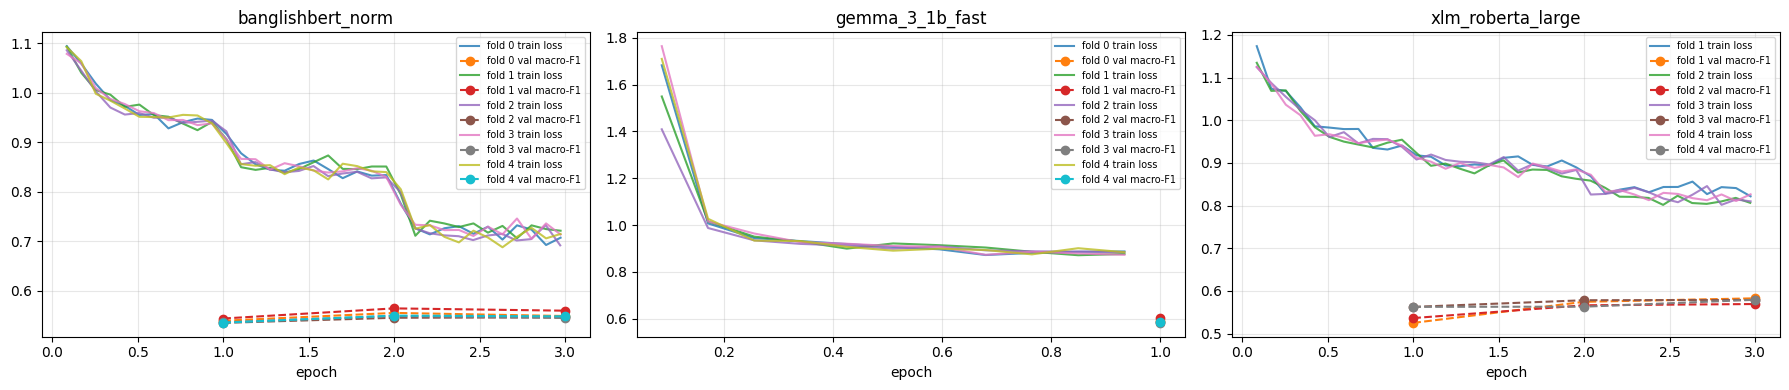

14 fold histories plotted -> results/figures/loss_curves.png


In [34]:
# ============================================================
# 10.8a Loss curves per model and fold
# ============================================================
import matplotlib.pyplot as plt
train_df, test_df = C.load_data(); y = train_df["y"].values
hist_files = sorted(glob.glob(f"{C.HISTORY_DIR}/*_f[0-9].csv"))
hist = pd.concat([pd.read_csv(f) for f in hist_files]) if hist_files else pd.DataFrame()
if hist.empty:
    print("no training history yet (run section 10 first)")
else:
    models_h = sorted(hist["model"].unique())
    fig, axes = plt.subplots(1, len(models_h), figsize=(6 * len(models_h), 4), squeeze=False)
    for ax, m in zip(axes[0], models_h):
        for k, h in hist[hist["model"] == m].groupby("fold"):
            tr = h.dropna(subset=["loss"])
            ax.plot(tr["epoch"], tr["loss"] / tr["grad_accum"], label=f"fold {k} train loss", alpha=0.8)
            ev = h.dropna(subset=["eval_macro_f1"])
            ax.plot(ev["epoch"], ev["eval_macro_f1"], "o--", label=f"fold {k} val macro-F1")
        ax.set_title(m); ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    plt.tight_layout()
    os.makedirs(C.FIG_DIR, exist_ok=True)
    plt.savefig(f"{C.FIG_DIR}/loss_curves.png", dpi=120); plt.show()
    print(f"{len(hist_files)} fold histories plotted -> results/figures/loss_curves.png")

> **Cell 10.8b.** We build the model comparison table (honest scores, per class, per language, runtime) and a bar chart.  
> **Output:** Gemma 0.5889 > XLM-R 0.5768 > BanglishBERT 0.5505 > TF-IDF 0.5264. The rows with `folds done 1` are old single-fold experiments we did not use.

            model  folds done  fold0 macro_f1  min per fold  total min      GPU  macro_f1   f1_0   f1_1   f1_2  f1_english  f1_bangla  f1_banglish  f1_mixed_script
  gemma_3_1b_fast           5          0.5900          47.5      237.7 Tesla T4    0.5889 0.6975 0.5339 0.5354      0.6362     0.4714       0.4123           0.4923
xlm_roberta_large           5          0.5740          29.8      119.0 Tesla T4    0.5768 0.6978 0.5121 0.5205      0.6191     0.4767       0.4505           0.5465
banglishbert_norm           5          0.5495           9.1       45.6 Tesla T4    0.5505 0.6711 0.5096 0.4708      0.5818     0.4770       0.4345           0.5036
         tfidf_lr           5          0.5218           0.9        4.3      CPU    0.5264 0.6459 0.5056 0.4276      0.5515     0.4521       0.4341           0.4713
     banglishbert           1          0.5499           NaN        NaN     None       NaN    NaN    NaN    NaN         NaN        NaN          NaN              NaN
 xlm_roberta_bas

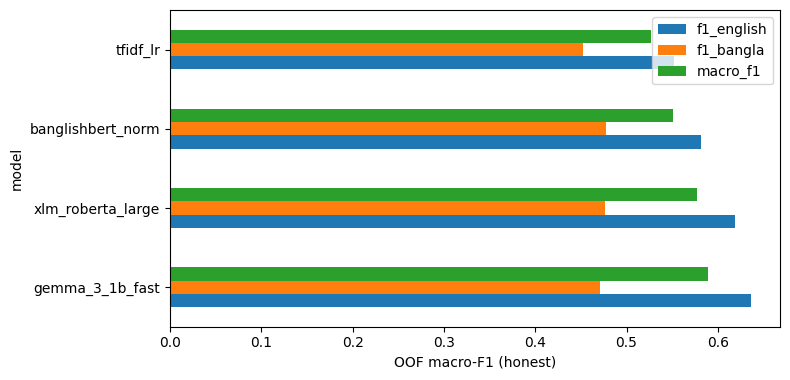

saved results/model_comparison.csv


In [35]:
# ============================================================
# 10.8b Model comparison table (honest OOF scores, runtime)
# ============================================================
os.makedirs(C.FIG_DIR, exist_ok=True)
runs = pd.read_csv(C.RUNLOG) if os.path.exists(C.RUNLOG) else pd.DataFrame(columns=["model", "fold"])
fold_runs = runs[runs["fold"].notna() & runs["model"].isin(C.list_models())].drop_duplicates(["model", "fold"], keep="last")
rows = []
for m in C.list_models():
    done = [k for k in range(C.N_FOLDS) if k not in C.missing_folds(m, train_df, test_df)]
    r = {"model": m, "folds done": len(done)}
    if len(done) == C.N_FOLDS:
        p = C.load_model_preds(m, train_df, test_df)[0].argmax(1)
        r.update({k: v for k, v in C.report(y, p, train_df["lang"].values, quiet=True).items() if k != "n"})
    elif 0 in done:          # fold-0 screens (soft labels, Gemma): fold 0 only, compare with the fold-0 column
        oof0 = pd.read_csv(C.pred_path("oof", m, 0)).set_index("id").loc[train_df.loc[train_df["fold"] == 0, "id"], C.COLS].values
        r["fold0 macro_f1"] = round(C.macro_f1(y[train_df["fold"] == 0], oof0.argmax(1)), 4)
    rt = fold_runs[fold_runs["model"] == m]["runtime_min"]
    r.update({"min per fold": round(rt.mean(), 1) if len(rt) else None, "total min": round(rt.sum(), 1) if len(rt) else None,
              "GPU": fold_runs[fold_runs["model"] == m]["gpu"].iloc[-1] if len(rt) else None})
    rows.append(r)
table = pd.DataFrame(rows)
for m in table["model"]:     # fold-0 score of every model, for comparison with the fold-0 screens
    p0 = pd.read_csv(C.pred_path("oof", m, 0)).set_index("id").loc[train_df.loc[train_df["fold"] == 0, "id"], C.COLS].values if C.fold_done(m, 0) else None
    table.loc[table["model"] == m, "fold0 macro_f1"] = round(C.macro_f1(y[train_df["fold"] == 0], p0.argmax(1)), 4) if p0 is not None else None
table = table.sort_values("macro_f1", ascending=False, na_position="last") if "macro_f1" in table else table
print(table.to_string(index=False))
C.write_csv(table, f"{C.RESULTS_DIR}/model_comparison.csv")
if "macro_f1" in table and table["macro_f1"].notna().any():
    t = table.dropna(subset=["macro_f1"])
    ax = t.plot.barh(x="model", y=["f1_english", "f1_bangla", "macro_f1"], figsize=(8, 0.6 * len(t) + 1.5))
    ax.set_xlabel("OOF macro-F1 (honest)"); plt.tight_layout(); plt.savefig(f"{C.FIG_DIR}/model_comparison.png", dpi=120); plt.show()
print("saved results/model_comparison.csv")

## 11. Tuning and ensembling

Different models make different mistakes, so a combination usually beats the best single model. In `src/ensemble.py` we:
1. blend the models' log-probabilities with weights (a weighted geometric mean);
2. add class shifts: small adjustments, up or down, to the subtle and neutral scores, because Macro F1 rewards getting the smaller classes right.

We tune the weights and shifts on 4 folds and score them on the 5th, rotating over all 5. A score tuned and measured on the same rows is optimistic, so we print it only for comparison and label it.
**Result:** all four models together reach an honest Macro F1 of **0.6057**; our best single model, Gemma, reaches 0.5889. Separate class shifts for Bangla posts did not help (-0.0003), so we do not use them.

> **Cell 11.1.** We write `src/ensemble.py`, our ensembling script.  
> **Output:** `Writing` or `Overwriting src/ensemble.py`.

In [36]:
%%writefile src/ensemble.py
# ============================================================
# 11.1 src/ensemble.py: honest weight + class-shift tuning, submission
# ============================================================
"""
ensemble.py - combine models honestly and write a submission (notebook sections 11-12)

Blend: weighted sum of the models' log-probabilities (a weighted geometric mean).
Tuning, on out-of-fold (OOF) predictions:
  1. weights: equal weights + random candidates (fixed seed); keep the best Macro F1
  2. class shifts: add b1 to class 1 and b2 to class 2 log-scores (grid -1.5..1.5,
     step 0.05); Macro F1 rewards getting the small classes right
  3. optional --lang_shifts: a separate class-shift pair for Bangla posts
     (Bangla posts are rarely neutral)

Honest score: tune on 4 folds, score the 5th, rotate over all 5 folds. The score
from tuning and scoring on the same rows is printed next to it, labelled
"optimistic". The final weights/shifts (tuned on all OOF rows) are applied to
the test predictions.

Refuses to run if any chosen model is missing a fold. Output names contain the
models used: results/ensemble_{tag}.json, submissions/sub_ens_{tag}.csv.
--use_overlap additionally writes sub_ens_{tag}_OVERLAP.csv, where test posts
that also appear in train take the (unambiguous) train label.
"""
VERSION = "2026-09-28.2"

import os, sys, time, argparse
if "--smoke" in sys.argv:
    os.environ["HERWILL_SMOKE"] = "1"
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np
import pandas as pd
import common as C

ap = argparse.ArgumentParser()
ap.add_argument("--models", required=True, help="comma-separated model names, e.g. tfidf_lr,xlm_roberta_large")
ap.add_argument("--lang_shifts", action="store_true", help="separate class shifts for Bangla posts")
ap.add_argument("--use_overlap", action="store_true", help="also write a submission using train labels of overlapping test posts")
ap.add_argument("--n_weights", type=int, default=1000, help="random weight candidates")
ap.add_argument("--overwrite", action="store_true")
ap.add_argument("--smoke", action="store_true")
args = ap.parse_args()
MODELS = args.models.split(",")
TAG = "+".join(MODELS) + ("_langshift" if args.lang_shifts else "") + ("_IDLEAK" if "id_neighbours" in MODELS else "")
JSON, SUB = f"{C.RESULTS_DIR}/ensemble_{TAG}.json", f"{C.SUB_DIR}/sub_ens_{TAG}.csv"
print(f"ensemble.py VERSION {VERSION} | common.py VERSION {C.VERSION} | smoke={C.SMOKE} | models {MODELS}")
if "id_neighbours" in MODELS:
    print("WARNING: id_neighbours uses row order (a leak), not text. Label any submission from it clearly.")
def fingerprint():
    """Size + modification time of every prediction file used: changes when any fold is retrained."""
    return {os.path.basename(C.pred_path(kind, m, k)): [os.path.getsize(C.pred_path(kind, m, k)), int(os.path.getmtime(C.pred_path(kind, m, k)))]
            for m in MODELS for k in range(C.N_FOLDS) for kind in ("oof", "test") if os.path.exists(C.pred_path(kind, m, k))}

expected = [JSON, SUB] + ([SUB.replace(".csv", "_OVERLAP.csv")] if args.use_overlap else [])
if all(os.path.exists(p) for p in expected) and not args.overwrite:
    import json
    if json.load(open(JSON)).get("inputs") == fingerprint():
        print(f"exists and its prediction files are unchanged, skipping: {os.path.relpath(JSON, C.ROOT)} (use --overwrite to redo)")
        sys.exit(0)
    print("prediction files changed since the last run (or no fingerprint saved): recomputing")
t0 = time.time()

# ---------------------------------------------------------------- load (refuses on missing folds)
train_df, test_df = C.load_data()
y, F = train_df["y"].values, train_df["fold"].values
is_bn = (train_df["lang"] == "bangla").values
is_bn_test = (test_df["lang"] == "bangla").values
loaded = [C.load_model_preds(m, train_df, test_df) for m in MODELS]
L_oof = np.stack([np.log(o + 1e-9) for o, _ in loaded])      # (models, rows, 3)
L_test = np.stack([np.log(t + 1e-9) for _, t in loaded])
for m, (o, _) in zip(MODELS, loaded):
    C.report(y, o.argmax(1), name=f"single model: {m}")

GRID = np.round(np.arange(-1.5, 1.5001, 0.05), 2)
rng = np.random.default_rng(C.SEED)
W_CAND = [np.ones(len(MODELS)) / len(MODELS)] + (list(rng.dirichlet(np.ones(len(MODELS)), size=args.n_weights))
                                                  if len(MODELS) > 1 else [])

def predict(p, L, bangla):
    s = np.tensordot(p["w"], L, axes=1) + np.array([0, *p["b"]])
    if p.get("b_bn") is not None:
        s[bangla] += np.array([0, *p["b_bn"]]) - np.array([0, *p["b"]])
    return s.argmax(1)

def best_shift(score, yy, extra_mask=None, base=None):
    """Grid search (b1, b2); with extra_mask only those rows get the new shift."""
    best, best_b = -1, (0.0, 0.0)
    for b1 in GRID:
        for b2 in GRID:
            s = score.copy()
            if extra_mask is None:
                s += np.array([0, b1, b2])
            else:
                s += np.where(extra_mask[:, None], np.array([0, b1, b2]), np.array([0, *base]))
            f = C.macro_f1(yy, s.argmax(1))
            if f > best:
                best, best_b = f, (float(b1), float(b2))
    return best_b

def tune(rows):
    L, yy = L_oof[:, rows], y[rows]
    w = max(W_CAND, key=lambda w: C.macro_f1(yy, np.tensordot(w, L, axes=1).argmax(1)))
    score = np.tensordot(w, L, axes=1)
    p = {"w": [round(float(v), 4) for v in w], "b": best_shift(score, yy)}
    p["b_bn"] = best_shift(score, yy, extra_mask=is_bn[rows], base=p["b"]) if args.lang_shifts else None
    return p

# ---------------------------------------------------------------- honest: tune on 4 folds, score the 5th
honest_pred, fold_params, fold_f1 = np.zeros(len(y), int), [], []
for k in range(C.N_FOLDS):
    p = tune(np.where(F != k)[0])
    va = F == k
    honest_pred[va] = predict(p, L_oof[:, va], is_bn[va])
    fold_params.append(p); fold_f1.append(round(float(C.macro_f1(y[va], honest_pred[va])), 4))
honest = C.report(y, honest_pred, train_df["lang"].values, name="HONEST (tuned on 4 folds)", show_cm=True)
print(f"{'':29s}per fold {fold_f1}")

# ---------------------------------------------------------------- final parameters: tuned on all OOF rows
final = tune(np.arange(len(y)))
optimistic = C.report(y, predict(final, L_oof, is_bn), name="optimistic (same rows)", quiet=True)
print(f"{'optimistic (same rows)':28s} macro-F1 {optimistic['macro_f1']:.4f}  <- tuned and scored on the same rows; NOT a real estimate")
print(f"final weights {dict(zip(MODELS, final['w']))} | class shifts (class 1, class 2) {final['b']}"
      + (f" | Bangla shifts {final['b_bn']}" if args.lang_shifts else ""))

test_pred = predict(final, L_test, is_bn_test)
sub = pd.DataFrame({"id": test_df["id"].values, "y_pred": test_pred.astype(int)})
C.write_csv(sub, SUB)
outputs = [SUB]
if args.use_overlap:
    ov = pd.read_csv(C.TEST_OVERLAP).dropna(subset=["train_label"])
    lab = dict(zip(ov["id"], ov["train_label"].astype(int)))
    sub_ov = sub.assign(y_pred=[lab.get(i, p) for i, p in zip(sub["id"], sub["y_pred"])])
    changed = int((sub_ov["y_pred"] != sub["y_pred"]).sum())
    outputs.append(C.write_csv(sub_ov, SUB.replace(".csv", "_OVERLAP.csv")))
    print(f"overlap: {int(sub['id'].isin(lab).sum())} test posts take their train label ({changed} predictions changed)")

C.write_json({"models": MODELS, "tag": TAG, "lang_shifts": args.lang_shifts, "leak": "id_neighbours" in MODELS,
              "final_weights": dict(zip(MODELS, final["w"])), "final_shifts": final["b"], "final_bangla_shifts": final["b_bn"],
              "honest": honest, "honest_per_fold": fold_f1, "optimistic_macro_f1": optimistic["macro_f1"],
              "fold_params": fold_params, "submission": os.path.relpath(SUB, C.ROOT),
              "test_class_mix": np.round(np.bincount(test_pred, minlength=3) / len(test_pred), 4).tolist(),
              "inputs": fingerprint(), "script_version": VERSION, "smoke": C.SMOKE}, JSON)
C.log_run(step="11_ensemble", model=f"ens:{TAG}", script_version=VERSION, gpu="CPU", smoke=C.SMOKE,
          runtime_min=round((time.time() - t0) / 60, 1), optimistic_macro_f1=optimistic["macro_f1"],
          weights=str(final["w"]), shifts=str(final["b"]), **honest)
print(f"wrote {[os.path.relpath(p, C.ROOT) for p in outputs + [JSON]]} ({(time.time() - t0) / 60:.1f} min)")

Overwriting src/ensemble.py


> **Cell 11.2.** We build and score each candidate combination of models, tuned on 4 folds and scored on the 5th.  
> **Output:** the final table, where all four models together reach HONEST 0.6057.

In [37]:
# ============================================================
# 11.2 Compare the candidate ensembles (honest scores)
# ============================================================
train_df, test_df = C.load_data()
ready = [c for c in ENSEMBLE_CANDIDATES if all(not C.missing_folds(m, train_df, test_df) for m in c)]
for c in ENSEMBLE_CANDIDATES:
    if c not in ready:
        print(f"skipped {c}: missing folds {({m: C.missing_folds(m, train_df, test_df) for m in c if C.missing_folds(m, train_df, test_df)})}")
for c in ready:
    run(f"src/ensemble.py --models {','.join(c)}{FLAGS}")

def ens_table():
    rows = []
    for f in sorted(glob.glob(f"{C.RESULTS_DIR}/ensemble_*.json")):
        j = json.load(open(f))
        rows.append({"ensemble": j["tag"], "HONEST macro_f1": j["honest"]["macro_f1"], "optimistic": j["optimistic_macro_f1"],
                     "f1 per class": [j["honest"][f"f1_{k}"] for k in range(3)], "bangla": j["honest"].get("f1_bangla"),
                     "weights": j["final_weights"], "shifts": j["final_shifts"]})
    return pd.DataFrame(rows).sort_values("HONEST macro_f1", ascending=False) if rows else pd.DataFrame()
print(ens_table().to_string(index=False) if len(ens_table()) else "no ensembles yet: every candidate still has missing folds")

$ python src/ensemble.py --models tfidf_lr,xlm_roberta_large
ensemble.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False | models ['tfidf_lr', 'xlm_roberta_large']
prediction files changed since the last run (or no fingerprint saved): recomputing
single model: tfidf_lr       macro-F1 0.5264 | per class 0.646 / 0.506 / 0.428 | n=47077
single model: xlm_roberta_large macro-F1 0.5768 | per class 0.698 / 0.512 / 0.520 | n=47077
HONEST (tuned on 4 folds)    macro-F1 0.5940 | per class 0.691 / 0.558 / 0.533 | n=47077
                             by language: english 0.634 | bangla 0.495 | banglish 0.476 | mixed_script 0.551
                             confusion (rows=true): [[15960, 6659, 609], [6262, 10419, 1308], [755, 2279, 2826]]
                             per fold [0.5936, 0.5989, 0.5833, 0.5962, 0.5977]
optimistic (same rows)       macro-F1 0.5944  <- tuned and scored on the same rows; NOT a real estimate
final weights {'tfidf_lr': 0.2923, 'xlm_roberta_large': 0.

> **Cell 11.3.** We test separate class shifts for Bangla posts on the best combination.  
> **Output:** `-0.0003`: no gain, so we do not use them.

In [38]:
# ============================================================
# 11.3 Optional check: separate class shifts for Bangla posts
# ============================================================
# Bangla posts are rarely neutral. We keep this only if the HONEST score rises; then set FINAL_LANG_SHIFTS = True.
best_c = max(ready, key=lambda c: json.load(open(f"{C.RESULTS_DIR}/ensemble_{ens_tag(c)}.json"))["honest"]["macro_f1"]) if ready else None
if best_c:
    run(f"src/ensemble.py --models {','.join(best_c)} --lang_shifts{FLAGS}")
    a = json.load(open(f"{C.RESULTS_DIR}/ensemble_{ens_tag(best_c)}.json"))["honest"]["macro_f1"]
    b = json.load(open(f"{C.RESULTS_DIR}/ensemble_{ens_tag(best_c, True)}.json"))["honest"]["macro_f1"]
    print(f"\nbest candidate {best_c}: honest {a:.4f} -> with Bangla shifts {b:.4f} ({b - a:+.4f})")
else:
    print("no complete ensemble candidate yet")

$ python src/ensemble.py --models tfidf_lr,xlm_roberta_large,banglishbert_norm,gemma_3_1b_fast --lang_shifts
ensemble.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False | models ['tfidf_lr', 'xlm_roberta_large', 'banglishbert_norm', 'gemma_3_1b_fast']
prediction files changed since the last run (or no fingerprint saved): recomputing
single model: tfidf_lr       macro-F1 0.5264 | per class 0.646 / 0.506 / 0.428 | n=47077
single model: xlm_roberta_large macro-F1 0.5768 | per class 0.698 / 0.512 / 0.520 | n=47077
single model: banglishbert_norm macro-F1 0.5505 | per class 0.671 / 0.510 / 0.471 | n=47077
single model: gemma_3_1b_fast macro-F1 0.5889 | per class 0.698 / 0.534 / 0.535 | n=47077
HONEST (tuned on 4 folds)    macro-F1 0.6054 | per class 0.702 / 0.559 / 0.555 | n=47077
                             by language: english 0.646 | bangla 0.492 | banglish 0.477 | mixed_script 0.584
                             confusion (rows=true): [[16494, 6173, 561], [6483, 1018

### 11.4 Optional, not used: id-neighbour labels (`USE_ID_NEIGHBOURS = False`)

In section 2.2 we saw that neighbouring ids are comments on the same video. `src/id_neighbours.py` predicts each post from the labels of training posts with nearby ids, without reading the text. It raises the score a lot, but it relies on how the file was ordered, would not work on new posts, and the rules do not mention it. We keep it off and include it only to document what we found.

> **Cell 11.4a.** We write `src/id_neighbours.py`, the row-order model we document but do not use.  
> **Output:** `Writing` or `Overwriting`.

In [39]:
%%writefile src/id_neighbours.py
# ============================================================
# 11.4a src/id_neighbours.py: optional row-order model (LEAK)
# ============================================================
"""
id_neighbours.py - OPTIONAL row-order model (notebook section 11, USE_ID_NEIGHBOURS)

The posts are scraped comment sections stored in id order: neighbouring ids are
comments on the same video, so they share topic and often label. This "model"
predicts a post from the labels of the TRAINING posts with nearby ids.

It does not read the text at all. It exploits how the data file was ordered
(a leak), the competition rules do not mention it, and it would not work on
new posts. It is therefore off by default and its outputs are named
id_neighbours, so any ensemble or submission using it is clearly labelled.

Honest out-of-fold scores: for fold k, the features of both training and
validation rows are built only from training-fold labels (a row never sees its
own label). Test features use all training labels.
Writes preds/oof_id_neighbours_f{k}.csv + preds/test_id_neighbours_f{k}.csv.
"""
VERSION = "2026-09-28.2"

import os, sys, time, argparse
if "--smoke" in sys.argv:
    os.environ["HERWILL_SMOKE"] = "1"
sys.path.insert(0, os.path.dirname(os.path.abspath(__file__)))
import numpy as np
from sklearn.linear_model import LogisticRegression
import common as C

ap = argparse.ArgumentParser()
ap.add_argument("--overwrite", action="store_true")
ap.add_argument("--smoke", action="store_true")
args = ap.parse_args()
NAME, WINDOWS = "id_neighbours", (3, 10, 30, 100)
print(f"id_neighbours.py VERSION {VERSION} | common.py VERSION {C.VERSION} | smoke={C.SMOKE} | windows +/-{WINDOWS} ids")

def features(query_ids, ref_ids, ref_y):
    """Share of each label among reference rows within +/-w ids (self excluded), per window."""
    order = np.argsort(ref_ids); r, ry = ref_ids[order], ref_y[order]
    cum = np.vstack([np.zeros(3), np.cumsum(np.eye(3)[ry], axis=0)])
    is_ref = np.isin(query_ids, r)
    out = []
    for w in WINDOWS:
        cnt = cum[np.searchsorted(r, query_ids + w, "right")] - cum[np.searchsorted(r, query_ids - w, "left")]
        cnt[is_ref] -= np.eye(3)[ry[np.searchsorted(r, query_ids[is_ref])]]
        out.append((cnt + 1) / (cnt.sum(1, keepdims=True) + 3))     # smoothed label shares
    return np.hstack(out)

train_df, test_df = C.load_data()
ids, y, F = train_df["id"].values, train_df["y"].values, train_df["fold"].values
for k in range(C.N_FOLDS):
    if C.fold_done(NAME, k) and not args.overwrite:
        print(f"fold {k}: exists, skipping"); continue
    t0 = time.time()
    tr, va = F != k, F == k
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=C.SEED)
    clf.fit(features(ids[tr], ids[tr], y[tr]), y[tr])
    va_prob = clf.predict_proba(features(ids[va], ids[tr], y[tr]))
    te_prob = clf.predict_proba(features(test_df["id"].values, ids[tr], y[tr]))
    res = C.report(y[va], va_prob.argmax(1), train_df["lang"].values[va], name=f"{NAME} fold {k}")
    C.save_preds("oof", NAME, va_prob, ids[va], fold=k, overwrite=args.overwrite)
    C.save_preds("test", NAME, te_prob, test_df["id"].values, fold=k, overwrite=args.overwrite)
    C.log_run(step="11_id_neighbours", model=NAME, script_version=VERSION, fold=k, gpu="CPU",
              runtime_min=round((time.time() - t0) / 60, 2), smoke=C.SMOKE, leak=True, **res)
oof, _ = C.load_model_preds(NAME, train_df, test_df)
C.report(y, oof.argmax(1), train_df["lang"].values, name=f"{NAME} OOF (LEAK, no text)")

Overwriting src/id_neighbours.py


> **Cell 11.4b.** This cell runs the row-order experiment only if `USE_ID_NEIGHBOURS = True`; we left it off.  
> **Output:** `skipped`.

In [40]:
# ============================================================
# 11.4b Run the id-neighbour model and a leak ensemble (only if USE_ID_NEIGHBOURS)
# ============================================================
if USE_ID_NEIGHBOURS:
    run("src/id_neighbours.py" + FLAGS)
    leak_models = [m for m in FINAL_MODELS if not C.missing_folds(m, train_df, test_df)] + ["id_neighbours"]
    run(f"src/ensemble.py --models {','.join(leak_models)}{FLAGS}")
    print(ens_table().to_string(index=False))
else:
    print("skipped (USE_ID_NEIGHBOURS = False)")

skipped (USE_ID_NEIGHBOURS = False)


## 12. Final validation and submission

We build the final submission from `FINAL_MODELS` (all four models, set in the config cell), check it against `sample_submission.csv`, and print which models, weights and class shifts produced it, so the result can be reproduced and explained.
We chose the final models by the honest score in 11.2, not by the public leaderboard, because picking repeatedly by leaderboard score can overfit it.

> **Cell 12.1.** We build the final submission from the four models in `FINAL_MODELS`, reusing the ensemble from 11.2 when nothing changed.  
> **Output:** `exists and its prediction files are unchanged, skipping`, or a freshly written file.

In [41]:
# ============================================================
# 12.1 Build the final submission
# ============================================================
train_df, test_df = C.load_data()
missing = {m: C.missing_folds(m, train_df, test_df) for m in FINAL_MODELS}
if any(missing.values()):
    raise RuntimeError(f"FINAL_MODELS has incomplete models {missing}: finish their folds or change FINAL_MODELS in the config cell")
run(f"src/ensemble.py --models {','.join(FINAL_MODELS)}" + (" --lang_shifts" if FINAL_LANG_SHIFTS else "")
    + (" --use_overlap" if USE_OVERLAP else "") + FLAGS)
final_tag = ens_tag(FINAL_MODELS, FINAL_LANG_SHIFTS)
final = json.load(open(f"{C.RESULTS_DIR}/ensemble_{final_tag}.json"))

$ python src/ensemble.py --models tfidf_lr,xlm_roberta_large,banglishbert_norm,gemma_3_1b_fast
ensemble.py VERSION 2026-09-28.2 | common.py VERSION 2026-09-28.2 | smoke=False | models ['tfidf_lr', 'xlm_roberta_large', 'banglishbert_norm', 'gemma_3_1b_fast']
exists and its prediction files are unchanged, skipping: results/ensemble_tfidf_lr+xlm_roberta_large+banglishbert_norm+gemma_3_1b_fast.json (use --overwrite to redo)


> **Cell 12.2.** We check the submission file against the official sample and print how it was made.  
> **Output:** four `OK` lines, the file name, models, weights, class shifts and HONEST Macro F1 0.6057.

In [42]:
# ============================================================
# 12.2 Check the file and print how it was made
# ============================================================
import shutil
sub_path = f"{C.ROOT}/{final['submission']}"
if USE_OVERLAP:
    sub_path = sub_path.replace(".csv", "_OVERLAP.csv")
sub = pd.read_csv(sub_path)
sample = pd.read_csv(C.SAMPLE_SUB)
if C.SMOKE:
    sample = sample[sample["id"].isin(test_df["id"])].reset_index(drop=True)
checks = {"columns id, y_pred": list(sub.columns) == ["id", "y_pred"],
          "same ids, same order as sample_submission": len(sub) == len(sample) and (sub["id"].values == sample["id"].values).all(),
          "labels only 0 / 1 / 2": sub["y_pred"].isin([0, 1, 2]).all(),
          "no missing values": not sub.isna().any().any()}
for k, v in checks.items():
    print(f"  {'OK ' if v else 'FAIL'} {k}")
assert all(checks.values()), "submission check failed"

final_file = f"{C.SUB_DIR}/FINAL_{final_tag}{'_OVERLAP' if USE_OVERLAP else ''}.csv"
shutil.copy(sub_path, final_file)
mix = sub["y_pred"].value_counts(normalize=True).sort_index().round(3).tolist()
print(f"\nFINAL SUBMISSION: {os.path.relpath(final_file, C.ROOT)}  ({len(sub):,} rows)")
print(f"  models          : {final['models']}")
print(f"  weights         : {final['final_weights']}")
print(f"  class shifts    : class 1 {final['final_shifts'][0]:+.2f}, class 2 {final['final_shifts'][1]:+.2f}"
      + (f" | Bangla {final['final_bangla_shifts']}" if final['final_bangla_shifts'] else ""))
print(f"  HONEST macro-F1 : {final['honest']['macro_f1']:.4f} (per fold {final['honest_per_fold']}) | optimistic {final['optimistic_macro_f1']:.4f}")
print(f"  overlap labels  : {'USED' if USE_OVERLAP else 'not used'} | id-neighbour leak: {'USED' if final['leak'] else 'not used'}")
print(f"  predicted class mix {mix} vs train {train_df['y'].value_counts(normalize=True).sort_index().round(3).tolist()}")

  OK  columns id, y_pred
  OK  same ids, same order as sample_submission
  OK  labels only 0 / 1 / 2
  OK  no missing values

FINAL SUBMISSION: submissions/FINAL_tfidf_lr+xlm_roberta_large+banglishbert_norm+gemma_3_1b_fast.csv  (11,955 rows)
  models          : ['tfidf_lr', 'xlm_roberta_large', 'banglishbert_norm', 'gemma_3_1b_fast']
  weights         : {'tfidf_lr': 0.1591, 'xlm_roberta_large': 0.2536, 'banglishbert_norm': 0.1424, 'gemma_3_1b_fast': 0.4449}
  class shifts    : class 1 +0.05, class 2 +0.00
  HONEST macro-F1 : 0.6057 (per fold [0.6081, 0.6126, 0.6024, 0.6022, 0.6021]) | optimistic 0.6067
  overlap labels  : not used | id-neighbour leak: not used
  predicted class mix [0.508, 0.38, 0.112] vs train [0.493, 0.382, 0.124]


> **Cell 12.3.** We add up the measured training time of the final models from the run log.  
> **Output:** about 6.8 hours of T4 training time (XLM-R fold 0 was timed in our first session, so it is not in this log).

In [43]:
# ============================================================
# 12.3 Measured runtime to reproduce the final submission
# ============================================================
runs = pd.read_csv(C.RUNLOG)
used = runs[runs["model"].isin(final["models"]) & runs["fold"].notna()].drop_duplicates(["model", "fold"], keep="last")
per_model = used.groupby("model")["runtime_min"].agg(["count", "sum"]).rename(columns={"count": "folds", "sum": "minutes"})
print(per_model.round(1).to_string())
print(f"measured training time for the final models: {per_model['minutes'].sum():.0f} min ({per_model['minutes'].sum() / 60:.1f} h) "
      f"(+ setup, cleaning and ensembling: a few minutes)")

                   folds  minutes
model                            
banglishbert_norm      5     45.6
gemma_3_1b_fast        5    237.7
tfidf_lr               5      4.3
xlm_roberta_large      4    119.0
measured training time for the final models: 407 min (6.8 h) (+ setup, cleaning and ensembling: a few minutes)


**Our two Kaggle picks:** (1) the four-model ensemble above (honest 0.6057) and (2) as a backup, the three-model ensemble without Gemma (honest 0.5960, `submissions/sub_ens_tfidf_lr+xlm_roberta_large+banglishbert_norm.csv`). Neither uses the optional overlap or id-neighbour steps.

## 13. Summary for presentation

A short summary of the problem, our method and model choices, the results, the challenges and what we would improve. The cell below fills in the numbers from the saved results (`results/summary.md`).

> **Cell 13.1.** We write the presentation summary, filling in the numbers from the saved results.  
> **Output:** the summary below the cell (also saved as `results/summary.md`).

In [44]:
# ============================================================
# 13.1 Presentation summary (numbers filled from the saved results)
# ============================================================
from IPython.display import Markdown, display
train_df, test_df = C.load_data()
n_train_raw, n_test_raw = len(pd.read_csv(C.TRAIN_RAW)), len(pd.read_csv(C.TEST_RAW))
final = json.load(open(f"{C.RESULTS_DIR}/ensemble_{ens_tag(FINAL_MODELS, FINAL_LANG_SHIFTS)}.json"))
comp = pd.read_csv(f"{C.RESULTS_DIR}/model_comparison.csv") if os.path.exists(f"{C.RESULTS_DIR}/model_comparison.csv") else pd.DataFrame()
model_lines = "\n".join(f"| {r['model']}{' (LEAK: row order, not text)' if r['model'] == 'id_neighbours' else ''} | {r.get('macro_f1', float('nan')):.4f} | {r.get('f1_english', float('nan')):.3f} | "
                        f"{r.get('f1_bangla', float('nan')):.3f} | {r.get('min per fold', float('nan'))} |"
                        for _, r in comp.iterrows() if pd.notna(r.get("macro_f1")))
h = final["honest"]
summary = f"""
### Problem
Classify {n_train_raw:,} Bangla, English and Banglish social-media posts (plus {n_test_raw:,} test posts) as explicitly toxic, subtly toxic or neutral. Metric: Macro F1. The neutral class is small (12%, only 7% in Bangla) and explicit vs subtle is a matter of tone.

### Data work
- Dropped one 42,000-character pasted chat dump; merged near-duplicates (89 texts had conflicting labels).
- 5 frozen folds grouped by near-duplicate text, stratified by class x language, so copies never leak across folds.
- Found that ids follow the scraped comment sections (~100-250 posts per video); kept it out of the main model because it is row order, not language.

### Method
- Baseline: TF-IDF (character + word n-grams) + logistic regression.
- Transformers: XLM-RoBERTa large (multilingual) and BanglishBERT (pretrained on Bangla and English, with its text normalizer); fixed 3 epochs, class-weighted loss with label smoothing, fp16 on a T4.
{"- Gemma 3 1B (decoder LLM) fine-tuned with LoRA (1 epoch, 64 tokens, fp32) as a fourth, different member." + chr(10) if "gemma_3_1b_fast" in final["models"] else ""}- Ensemble: weighted log-probability blend + class shifts, tuned on 4 folds and scored on the 5th (honest).

### Results (honest out-of-fold Macro F1)
| Model | Macro F1 | English | Bangla | min per fold (T4) |
|---|---|---|---|---|
{model_lines}
| **Final ensemble: {" + ".join(final["models"])}** | **{h["macro_f1"]:.4f}** | {h.get("f1_english", float("nan")):.3f} | {h.get("f1_bangla", float("nan")):.3f} | |

Per class (final): explicit {h["f1_0"]:.3f}, subtle {h["f1_1"]:.3f}, neutral {h["f1_2"]:.3f}.

### Challenges
- Label noise: identical posts with different labels; explicit vs subtle is often ambiguous.
- Bangla neutral posts are rare and the weakest group.
- Reproducibility: the fold split changed with the scikit-learn version, so it is pinned to 1.7.2; every run is logged in `results/runs.csv`.

### Improvements with more time
- Soft labels (a TF-IDF second opinion mixed into the targets): +0.0075 for TF-IDF, untested on transformers.
{"- Gemma with 2 epochs and 128 tokens (we used 1 epoch / 64 tokens to fit the deadline on a free T4)." if "gemma_3_1b_fast" in final["models"] else "- A small LLM (Gemma 3 1B with LoRA) as an extra ensemble member."}
- More seeds per model; a stricter "unseen video" validation.
"""
os.makedirs(C.RESULTS_DIR, exist_ok=True)
open(f"{C.RESULTS_DIR}/summary.md", "w").write(summary)
display(Markdown(summary))


### Problem
Classify 47,817 Bangla, English and Banglish social-media posts (plus 11,955 test posts) as explicitly toxic, subtly toxic or neutral. Metric: Macro F1. The neutral class is small (12%, only 7% in Bangla) and explicit vs subtle is a matter of tone.

### Data work
- Dropped one 42,000-character pasted chat dump; merged near-duplicates (89 texts had conflicting labels).
- 5 frozen folds grouped by near-duplicate text, stratified by class x language, so copies never leak across folds.
- Found that ids follow the scraped comment sections (~100-250 posts per video); kept it out of the main model because it is row order, not language.

### Method
- Baseline: TF-IDF (character + word n-grams) + logistic regression.
- Transformers: XLM-RoBERTa large (multilingual) and BanglishBERT (pretrained on Bangla and English, with its text normalizer); fixed 3 epochs, class-weighted loss with label smoothing, fp16 on a T4.
- Gemma 3 1B (decoder LLM) fine-tuned with LoRA (1 epoch, 64 tokens, fp32) as a fourth, different member.
- Ensemble: weighted log-probability blend + class shifts, tuned on 4 folds and scored on the 5th (honest).

### Results (honest out-of-fold Macro F1)
| Model | Macro F1 | English | Bangla | min per fold (T4) |
|---|---|---|---|---|
| gemma_3_1b_fast | 0.5889 | 0.636 | 0.471 | 47.5 |
| xlm_roberta_large | 0.5768 | 0.619 | 0.477 | 29.8 |
| banglishbert_norm | 0.5505 | 0.582 | 0.477 | 9.1 |
| tfidf_lr | 0.5264 | 0.551 | 0.452 | 0.9 |
| **Final ensemble: tfidf_lr + xlm_roberta_large + banglishbert_norm + gemma_3_1b_fast** | **0.6057** | 0.646 | 0.500 | |

Per class (final): explicit 0.700, subtle 0.561, neutral 0.556.

### Challenges
- Label noise: identical posts with different labels; explicit vs subtle is often ambiguous.
- Bangla neutral posts are rare and the weakest group.
- Reproducibility: the fold split changed with the scikit-learn version, so it is pinned to 1.7.2; every run is logged in `results/runs.csv`.

### Improvements with more time
- Soft labels (a TF-IDF second opinion mixed into the targets): +0.0075 for TF-IDF, untested on transformers.
- Gemma with 2 epochs and 128 tokens (we used 1 epoch / 64 tokens to fit the deadline on a free T4).
- More seeds per model; a stricter "unseen video" validation.
